# 03 — Recommendation Prototype

**November: Milestone 4 (Recommendation Prototype).**

| Task | What it does | Target | Section |
|---|---|---|---|
| 11 | Define the recommendation approach and identify risk factors | 11/6 | Task 11 |
| 12 | Connect predictions to recommendations (rules and logic) | 11/13 | Task 12 |
| 13 | Build the initial recommendation prototype | 11/18 | Task 13 |
| 14 | Test the prototype on sample campaigns and improve it | 11/24 | Task 14 |
| 15 | Final validation of the model and the recommendations | 11/30 | Task 15 |

This notebook replaces `10_approach_and_risk_factors`, `11_recommendation_logic`,
`12_prototype`, `13_test_and_improve` and `14_validation`; each became one
section, in order. Section numbers match task numbers. The engine itself lives
in `src/recommend.py`.

**What changed when the final model started using `updates`.** The prototype
used to refuse `updates` as post-launch information. It now **requires** it as
the number of updates the creator *plans* to post, because the final model
scores with it. It is never recommended as a change: update counts partly
reflect how well a campaign was already going. Every report says how much the
chance depends on that plan. Outcome fields (`pledged`, `backers`,
`comments`, `funded_percentage`) are still refused.

Run it top to bottom; it took about 15 minutes on one CPU core.

**Writes:** the `m4_*` files in `reports/` and the `m4_*` figures.

## Setup

In [1]:
import sys
import json
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import roc_auc_score

from src.data import load_splits
from src.features import CAMPAIGN_NUMERIC, FINAL_FEATURE_SET, LEAKY_COLUMNS, model_matrices
from src.modeling import (FINAL_MODEL_NAME, evaluate, majority_class_baseline, make_final_model)
from src.recommend import (
    BANDS, DEFAULT_DURATION, DURATION_TARGETS, GOAL_FACTORS, GOAL_FLOOR_QUANTILE, MIN_GAIN,
    MIN_TIER_ADDITION, NICE_AMOUNTS, OUTCOME_FIELDS, RAW_COLUMNS, TIER_TARGETS, Recommender,
    campaign_from_row, string_to_tiers, suggest_tiers, tiers_to_string,
)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
TEAL, PLUM, CORAL, SAND = "#2E7D6F", "#7B5EA7", "#C0392B", "#D9A455"
FIG = Path("../reports/figures")
REPORTS = Path("../reports")

splits = load_splits("..")
train, test = splits["random"]
train_c, test_c = splits["chronological"]
rec = Recommender.fit(train, test=test)      # the prototype: scorer + advisor
raw_test = test[RAW_COLUMNS].copy()
print(f"train {len(train):,}   test {len(test):,}   features {len(rec.columns)}")
print(f"Prototype inputs: {RAW_COLUMNS}")

train 30,702   test 7,676   features 138
Prototype inputs: ['goal', 'duration', 'levels', 'reward_levels', 'category', 'subcategory', 'state_raw', 'city', 'launch_date', 'name', 'updates']


## Task 11 — Recommendation Approach and Risk Factors

**Milestone 4 · Task 11.** Define how model predictions and EDA findings
become recommendations, and identify the factors associated with campaigns
being predicted as at risk.

**Goal of Milestone 4** (from the challenge brief): *explore how predictions
and insights from successful campaigns could be translated into actionable
recommendations for campaigns predicted to be at risk.*

The final model is the **tuned, calibrated Random Forest** on the
`with_updates` feature set, chosen in Milestone 3 (Task 10). The prototype pairs it with the Milestone 3
**Logistic Regression as an advisor** that estimates what-if effects — §11.8
shows why a forest cannot do that job on its own.

This notebook settles three things before any recommendation is written:

1. What a creator can and cannot change
2. What the evidence says about each thing they can change
3. Why the advice comes from *what-if predictions* rather than from reading
   model coefficients

### 11.1 The final model, re-measured

Re-computed here rather than quoted, so this notebook stands on its own.

In [2]:
_, _, X_test, y_test = model_matrices(train, test, FINAL_FEATURE_SET)
assert list(X_test.columns) == rec.columns      # identical to the prototype's matrix
perf = pd.concat([
    majority_class_baseline(train["success"], test["success"]),
    evaluate(rec.model, X_test, y_test, label=FINAL_MODEL_NAME,
             feature_set=FINAL_FEATURE_SET, split="random"),
], ignore_index=True)
perf.round(4)

,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
0,Majority class,—,—,0.5473,0.5473,1.0000,0.7074,0.5000
1,Random Forest (tuned + calibrated),with_updates,random,0.8155,0.8214,0.8472,0.8341,0.8976


**81.6% accuracy against a 54.7% floor**, ROC-AUC 0.898: the same numbers as
Task 10 in notebook 02. That accuracy uses each held-out campaign's actual
final update count. Before launch the prototype scores the number of updates a
creator *plans*, and how closely plans match outcomes is not in this data, so
the probability is conditional on the plan being kept.

### 11.2 Can the probability be trusted?

A recommendation prototype shows a probability to a person, so calibration
matters as much as accuracy. If it says 30%, roughly 30% of campaigns scored
that way should succeed.

                                predicted  observed    n  gap_pp
(0.009000000000000001, 0.0418]      0.017     0.027  786   0.950
(0.0418, 0.152]                     0.096     0.073  770  -2.331
(0.152, 0.268]                      0.207     0.185  752  -2.221
(0.268, 0.439]                      0.350     0.387  765   3.675
(0.439, 0.614]                      0.529     0.516  770  -1.298
(0.614, 0.751]                      0.693     0.717  777   2.400
(0.751, 0.866]                      0.815     0.774  757  -4.092
(0.866, 0.912]                      0.892     0.884  764  -0.831
(0.912, 0.948]                      0.930     0.949  767   1.873
(0.948, 0.99]                       0.969     0.971  768   0.213

Largest gap in any decile: 4.1 percentage points


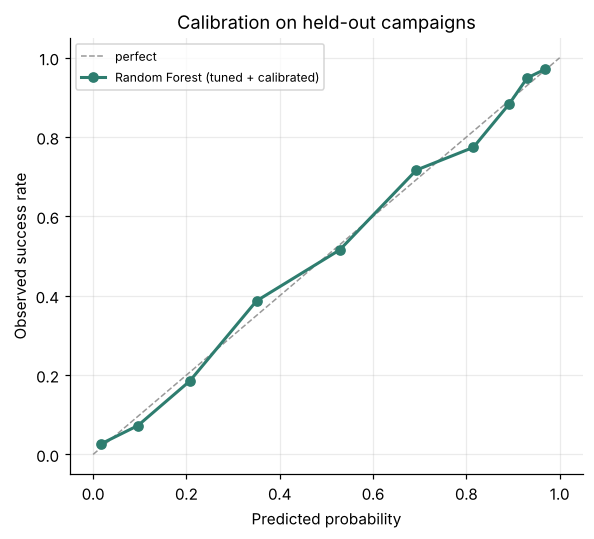

In [3]:
p, y = rec.holdout_p, rec.holdout_y
deciles = pd.qcut(p, 10, duplicates="drop")
cal = (pd.DataFrame({"p": p, "y": y}).groupby(deciles, observed=True)
       .agg(predicted=("p", "mean"), observed=("y", "mean"), n=("y", "size")))
cal["gap_pp"] = (cal["observed"] - cal["predicted"]) * 100
print(cal.round(3).to_string())
print(f"\nLargest gap in any decile: {cal['gap_pp'].abs().max():.1f} percentage points")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color="#999", ls="--", lw=1, label="perfect")
ax.plot(cal["predicted"], cal["observed"], marker="o", color=TEAL, lw=2,
        label=FINAL_MODEL_NAME)
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed success rate")
ax.set_title("Calibration on held-out campaigns"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m4_calibration.png", dpi=130, bbox_inches="tight")
plt.show()

Every decile is within 4.1 points, so the probabilities can be shown at face
value, with two caveats: individual predictions still carry real uncertainty
(ROC-AUC is 0.898, not 0.99), and the chance shown is kept between 1% and 99%
(Task 14, row 17), which is why the lowest bin starts at 1%.

### 11.3 Risk bands

Three bands, defined by predicted probability. The observed success rate for
each is measured on held-out campaigns, so a band label always comes with
what actually happened to campaigns scored there.

In [4]:
bands = pd.DataFrame([{"band": k, "predicted range": f"{v['range'][0]:.0%} to {v['range'][1]:.0%}",
                       "held-out campaigns": v["n"],
                       "observed success": f"{v['observed_rate']:.1%}"}
                      for k, v in rec.band_rates.items()])
bands

,band,predicted range,held-out campaigns,observed success
0,High risk,0% to 35%,2708,13.4%
1,Moderate risk,35% to 55%,855,45.7%
2,Favourable,55% to 100%,4113,83.8%


The bands separate cleanly: **13.4%** of campaigns scored High risk
succeeded, **45.7%** of Moderate risk and **83.8%** of Favourable. "At risk",
for the rest of this milestone, means High or Moderate risk.

### 11.4 What a creator can and cannot change

Advice is only useful about decisions that are still open. Everything the
model uses is known at launch, but not everything is changeable.

In [5]:
pd.DataFrame([
    ("Goal", "Yes", "Funding target in dollars", "**Lever**"),
    ("Duration", "Yes", "Campaign length in days (1-60)", "**Lever**"),
    ("Reward tiers", "Yes", "Number of tiers and their price points", "**Lever**"),
    ("Category / subcategory", "No", "What the project is", "Informs the prediction only"),
    ("State / city", "No", "Where the creator is based", "Informs the prediction only"),
    ("Launch date", "Partly", "Effect is weak and confounded with platform drift", "Held fixed, never advised"),
    ("Title wording", "Partly", "Weak signal in September's analysis", "Not advised"),
    ("Planned updates", "Yes, as a plan", "How many updates the creator intends to post", "**Required input, never advised**"),
    ("Backers, pledged, comments, funded %", "n/a", "Outcomes; do not exist at launch", "**Cannot enter the tool**"),
], columns=["factor", "changeable?", "what it is", "role in the prototype"])

,factor,changeable?,what it is,role in the prototype
0,Goal,Yes,Funding target in dollars,**Lever**
1,Duration,Yes,Campaign length in days (1-60),**Lever**
2,Reward tiers,Yes,Number of tiers and their price points,**Lever**
3,Category / subcategory,No,What the project is,Informs the prediction only
4,State / city,No,Where the creator is based,Informs the prediction only
5,Launch date,Partly,Effect is weak and confounded with platform drift,"Held fixed, never advised"
6,Title wording,Partly,Weak signal in September's analysis,Not advised
7,Planned updates,"Yes, as a plan",How many updates the creator intends to post,"**Required input, never advised**"
8,"Backers, pledged, comments, funded %",n/a,Outcomes; do not exist at launch,**Cannot enter the tool**


### 11.5 What the evidence says about each lever

All figures use the **training split only**. Where a pattern could be a
side-effect of goal size, it is shown *within goal quartiles* — cheap
projects ask for less and succeed more, so comparing across goal sizes would
mislead.

In [6]:
t = train.copy()
t["goal_q"] = pd.qcut(t["goal"], 4, labels=["Q1 (small)", "Q2", "Q3", "Q4 (large)"])

# --- goal
t["goal_decile"] = pd.qcut(t["goal"], 10, duplicates="drop")
goal_ev = t.groupby("goal_decile", observed=True).agg(
    median_goal=("goal", "median"), success=("success", "mean"), n=("success", "size"))

# --- reward tiers within goal quartile
t["tier_bucket"] = pd.cut(t["levels"], [0, 4, 7, 10, 100], labels=["<=4", "5-7", "8-10", "11+"])
tier_ev = t.pivot_table(index="goal_q", columns="tier_bucket", values="success",
                        aggfunc="mean", observed=True)

# --- duration within goal quartile
t["dur_bucket"] = pd.cut(t["duration_days"], [0, 29.5, 30.5, 45, 100],
                         labels=["<=29", "30 (default)", "31-45", ">45"])
dur_ev = t.pivot_table(index="goal_q", columns="dur_bucket", values="success",
                       aggfunc="mean", observed=True)

# --- entry price: raw gap vs the gap with goal size AND tier count held fixed
t["entry_b"] = pd.cut(t["min_tier"], [0, 10, 25, 1e9], labels=["<=$10", "$11-25", ">$25"])
t["tier_b"] = pd.cut(t["levels"], [0, 4, 7, 100], labels=["<=4", "5-7", "8+"])

def entry_gap(bucket, ref="<=$10", min_cell=30):
    """(raw gap, adjusted gap) in points, bucket minus reference.

    The adjusted gap compares campaigns only within cells of the same goal
    quartile and tier-count band, weighting each cell by the size of `bucket`.
    """
    raw = (t.loc[t["entry_b"] == bucket, "success"].mean()
           - t.loc[t["entry_b"] == ref, "success"].mean()) * 100
    g = t.groupby(["goal_q", "tier_b", "entry_b"], observed=True)["success"].agg(["mean", "size"])
    num = den = 0.0
    for (q, tb), _ in t.groupby(["goal_q", "tier_b"], observed=True):
        try:
            a, r = g.loc[(q, tb, bucket)], g.loc[(q, tb, ref)]
        except KeyError:
            continue
        if a["size"] >= min_cell and r["size"] >= min_cell:
            num += a["size"] * (a["mean"] - r["mean"]); den += a["size"]
    return raw, (num / den) * 100 if den else float("nan")

entry_ev = t.groupby("entry_b", observed=True).agg(
    success=("success", "mean"), n=("success", "size"),
    median_tiers=("levels", "median"), share_4_or_fewer_tiers=("levels", lambda s: (s <= 4).mean()))
entry_gaps = pd.DataFrame(
    {b: entry_gap(b) for b in ["$11-25", ">$25"]}, index=["raw gap (pts)", "gap with goal + tiers held fixed (pts)"]).T

print("GOAL — success by decile"); print(goal_ev.round(3).to_string())
print("\nREWARD TIERS — success by tier count, within goal quartile"); print(tier_ev.round(3).to_string())
print("\nDURATION — success by length, within goal quartile"); print(dur_ev.round(3).to_string())
print("\nENTRY PRICE — by cheapest tier"); print(entry_ev.round(3).to_string())
print("\nENTRY PRICE — gap versus a <=$10 entry, before and after holding goal and tier count fixed")
print(entry_gaps.round(1).to_string())

GOAL — success by decile
                       median_goal  success     n
goal_decile                                      
(0.999, 750.0]               500.0    0.712  3184
(750.0, 1250.0]             1000.0    0.668  3002
(1250.0, 2000.0]            1800.0    0.666  3673
(2000.0, 3000.0]            2700.0    0.625  3989
(3000.0, 4000.0]            3600.0    0.590  2262
(4000.0, 5000.0]            5000.0    0.513  3385
(5000.0, 7000.0]            6000.0    0.524  2057
(7000.0, 10000.0]          10000.0    0.469  3692
(10000.0, 20000.0]         15000.0    0.382  3042
(20000.0, 20000000.0]      35000.0    0.227  2416

REWARD TIERS — success by tier count, within goal quartile
tier_bucket    <=4    5-7   8-10    11+
goal_q                                 
Q1 (small)   0.614  0.694  0.740  0.795
Q2           0.402  0.601  0.678  0.773
Q3           0.153  0.445  0.570  0.687
Q4 (large)   0.074  0.236  0.364  0.515

DURATION — success by length, within goal quartile
dur_bucket   <=29  30 (

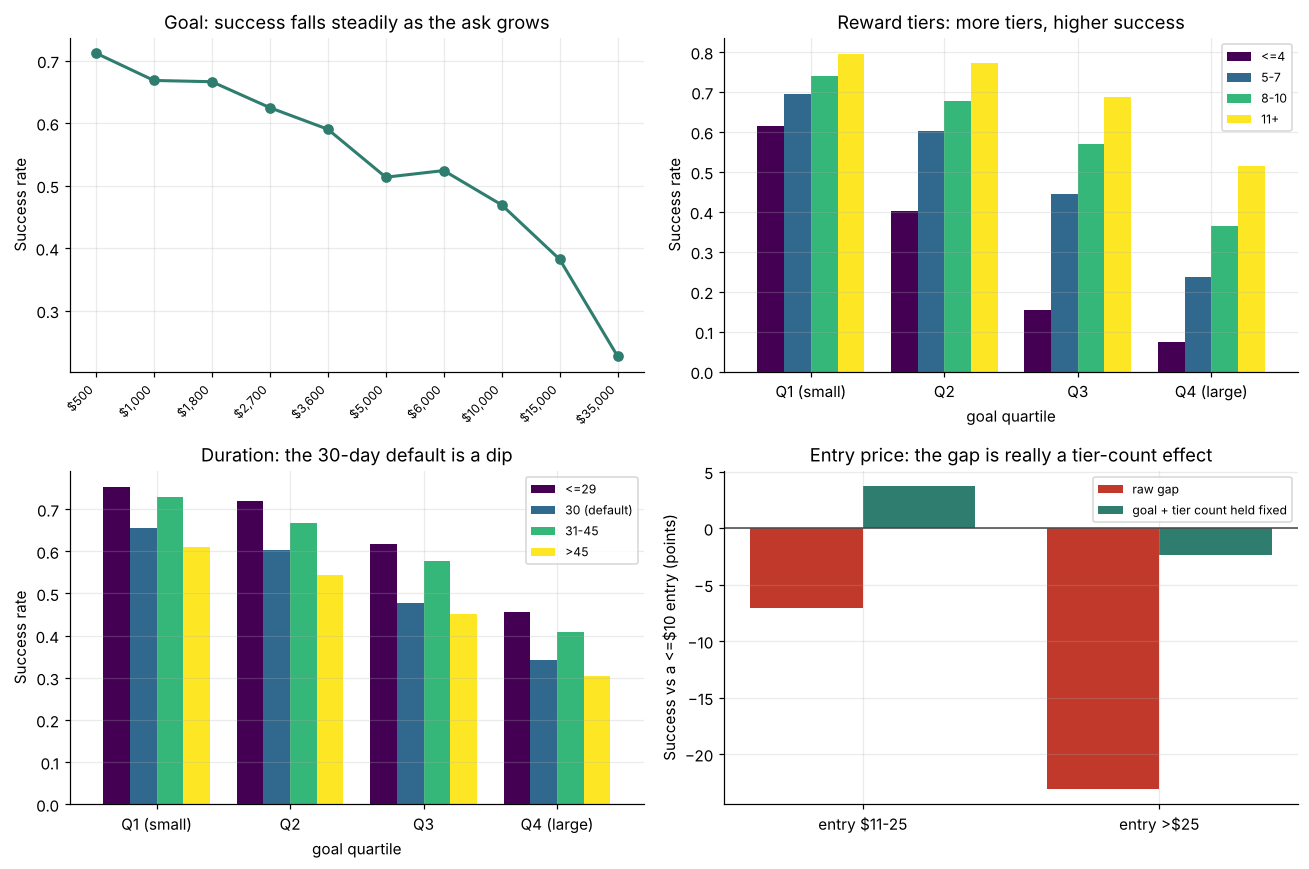

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

ax = axes[0, 0]
ax.plot(range(len(goal_ev)), goal_ev["success"], marker="o", color=TEAL, lw=2)
ax.set_xticks(range(len(goal_ev)))
ax.set_xticklabels([f"${v:,.0f}" for v in goal_ev["median_goal"]], rotation=45, ha="right", fontsize=8)
ax.set_title("Goal: success falls steadily as the ask grows"); ax.set_ylabel("Success rate")

for ax, ev, title in [(axes[0, 1], tier_ev, "Reward tiers: more tiers, higher success"),
                      (axes[1, 0], dur_ev, "Duration: the 30-day default is a dip")]:
    ev.plot.bar(ax=ax, width=0.8, rot=0, colormap="viridis")
    ax.set_title(title); ax.set_ylabel("Success rate"); ax.set_xlabel("goal quartile")
    ax.legend(fontsize=8, title=None)

ax = axes[1, 1]
x = np.arange(len(entry_gaps)); w = 0.38
ax.bar(x - w / 2, entry_gaps.iloc[:, 0], w, color=CORAL, label="raw gap")
ax.bar(x + w / 2, entry_gaps.iloc[:, 1], w, color=TEAL, label="goal + tier count held fixed")
ax.axhline(0, color="#444", lw=1)
ax.set_xticks(x); ax.set_xticklabels([f"entry {b}" for b in entry_gaps.index])
ax.set_ylabel("Success vs a <=$10 entry (points)")
ax.set_title("Entry price: the gap is really a tier-count effect"); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG / "m4_lever_evidence.png", dpi=130, bbox_inches="tight")
plt.show()

#### Reading the evidence

- **Goal** — a clean, monotonic decline. The most reliable relationship in
  the data.
- **Reward tiers** — the strongest effect, and it survives every goal
  quartile. A large-goal campaign with four or fewer tiers succeeds a small
  fraction of the time; with eleven or more it succeeds about half the time.
- **Duration** — longer campaigns do worse, **and exactly-30-day campaigns
  are a dip** relative to neighbouring durations, within every goal
  quartile. See §11.6.
- **Entry price** — campaigns with a high entry price do succeed less, but
  they also offer far fewer tiers (see the table above). Holding goal size
  and tier count fixed, the gap shrinks from -23 points to a few points, and
  its sign changes between buckets. **Entry price is not a separate lever;
  the tier count is.**

### 11.6 Four September statements that did not survive checking

While designing the levers, each claim from the September EDA that the
recommendations would lean on was re-tested against the data. Four were
wrong or overstated. They are corrected here and should be corrected in the
README and Tasks 4–5 in notebook 01.

In [8]:
full = pd.concat([train, test])
is30 = full["is_30_day"] == 1
min_hi = full["min_tier"] > 25
cheap = full.loc[full["min_tier"] <= 10, "success"].mean()

hi_gap = entry_gaps.loc[">$25"]
mid_gap = entry_gaps.loc["$11-25"]

# live check of the "just add a cheap tier" advice
from src.recommend import tiers_to_string, string_to_tiers
_raw = test[RAW_COLUMNS].copy()
_tiers = _raw["reward_levels"].map(string_to_tiers)
_m = _tiers.map(min).gt(25).to_numpy()
_new = [tiers_to_string(sorted(set(x + [10.0]))) if mm else s_
        for x, s_, mm in zip(_tiers, _raw["reward_levels"], _m)]
_r2 = _raw.copy(); _r2["reward_levels"] = _new; _r2["levels"] = [len(string_to_tiers(v)) for v in _new]
add_tier_gain = ((rec.what_if_proba(_raw, _r2) - rec.predict_proba(_raw)) * 100)[_m].mean()

# --- location: September called it modest, "a few points between best and worst states"
from scipy.stats import spearmanr
st = train.groupby("state_raw")["success"].agg(["mean", "size"])
st = st[st["size"] >= 150].sort_values("mean")
_gq = pd.qcut(train["goal"], 4, labels=False)
_res = (train["success"] - train.groupby(_gq)["success"].transform("mean"))
st_adj = _res.groupby(train["state_raw"]).agg(["mean", "size"])
st_adj = st_adj[st_adj["size"] >= 150]["mean"] * 100
city_q = train.groupby(pd.qcut(train["city_project_count"].rank(method="first"), 4,
                               labels=["smallest", "small-mid", "large-mid", "largest"]),
                       observed=True)["success"].mean()
rho_city = spearmanr(train["log_city_project_count"], train["success"]).statistic

corrections = pd.DataFrame([
    {"September statement": "The 30-day default outperforms",
     "what the data shows": (f"30-day campaigns succeed {full.loc[is30, 'success'].mean():.1%} "
                             f"vs {full.loc[~is30, 'success'].mean():.1%} for all others, and "
                             f"clearly less than 26-29 day campaigns within every goal quartile"),
     "verdict": "WRONG"},
    {"September statement": "A low entry price helps",
     "what the data shows": (f"Raw gap for a >$25 entry is {hi_gap.iloc[0]:+.1f} points, but "
                             f"{hi_gap.iloc[1]:+.1f} once goal size and tier count are held "
                             f"fixed. High-entry campaigns offer a median of "
                             f"{entry_ev.loc['>$25', 'median_tiers']:.0f} tiers vs "
                             f"{entry_ev.loc['<=$10', 'median_tiers']:.0f}"),
     "verdict": "OVERSTATED - it is a tier-count effect"},
    {"September statement": "Creators can simply add a $5 tier",
     "what the data shows": (f"Adding a $10 tier to campaigns with a >$25 entry moves the "
                             f"prediction by {add_tier_gain:+.1f} points; what helps is "
                             f"the number of tiers, not how cheap the cheapest one is"),
     "verdict": "NOT SUPPORTED as stated"},
    {"September statement": "Location is a modest signal (a few points between best and worst states; city density weak)",
     "what the data shows": (f"Across {len(st)} states with 150+ campaigns success runs from "
                             f"{st['mean'].iloc[0]:.0%} ({st.index[0]}) to {st['mean'].iloc[-1]:.0%} "
                             f"({st.index[-1]}), a {(st['mean'].iloc[-1] - st['mean'].iloc[0]) * 100:.0f}-point "
                             f"spread that is {st_adj.max() - st_adj.min():.0f} points after removing goal size. "
                             f"By city size the smallest quartile succeeds {city_q.iloc[0]:.0%} against "
                             f"{city_q.iloc[-1]:.0%} for the largest. A rank correlation of {rho_city:.2f} "
                             f"made it look weak; the rates show it is not"),
     "verdict": "WRONG"},
])
corrections

,September statement,what the data shows,verdict
0,The 30-day default outperforms,"30-day campaigns succeed 52.9% vs 55.5% for all others, and clearly less than 26-29 da...",WRONG
1,A low entry price helps,"Raw gap for a >$25 entry is -23.1 points, but -2.4 once goal size and tier count are h...",OVERSTATED - it is a tier-count effect
2,Creators can simply add a $5 tier,Adding a $10 tier to campaigns with a >$25 entry moves the prediction by -2.5 poi...,NOT SUPPORTED as stated
3,Location is a modest signal (a few points between best and worst states; city density ...,"Across 32 states with 150+ campaigns success runs from 37% (FL) to 65% (NY), a 27-poin...",WRONG


"More reward tiers help" **does** hold, strongly, and it is what the
recommendations lean on instead.

The lesson is worth keeping for the write-up: the September notebook printed
the correct numbers, but the interpretive sentence beside them had been
written before they were read. Findings in this project are now stated
from computed output, not the other way round.

### 11.7 Factors associated with campaigns predicted at risk

What do campaigns the model scores as high or moderate risk have in common?
This describes what the model sees as risky — it is *not* independent
evidence, since the bands were built from these same features. The
independent evidence is §11.5.

In [9]:
tt = test.copy()
tt["p"] = rec.holdout_p
tt["band"] = pd.cut(tt["p"], [0, BANDS[0][0], BANDS[1][0], 1.01],
                    labels=[b[1] for b in BANDS], right=False)

profile = tt.groupby("band", observed=True).agg(
    campaigns=("success", "size"),
    observed_success=("success", "mean"),
    median_goal=("goal", "median"),
    median_duration=("duration_days", "median"),
    median_tiers=("levels", "median"),
    share_4_or_fewer_tiers=("levels", lambda s: (s <= 4).mean()),
    share_over_45_days=("duration_days", lambda s: (s > 45).mean()),
    median_entry_price=("min_tier", "median"),
    median_updates=("updates", "median"),
    share_no_updates=("updates", lambda s: (s == 0).mean()),
)
profile.round(3).T

band,High risk,Moderate risk,Favourable
campaigns,2708.000,855.000,4113.000
observed_success,0.134,0.457,0.838
median_goal,6000.000,2400.000,3000.000
median_duration,37.710,30.160,30.960
median_tiers,7.000,7.000,8.000
share_4_or_fewer_tiers,0.230,0.204,0.101
share_over_45_days,0.363,0.256,0.233
median_entry_price,5.000,5.000,5.000
median_updates,0.000,1.000,5.000
share_no_updates,0.742,0.480,0.022


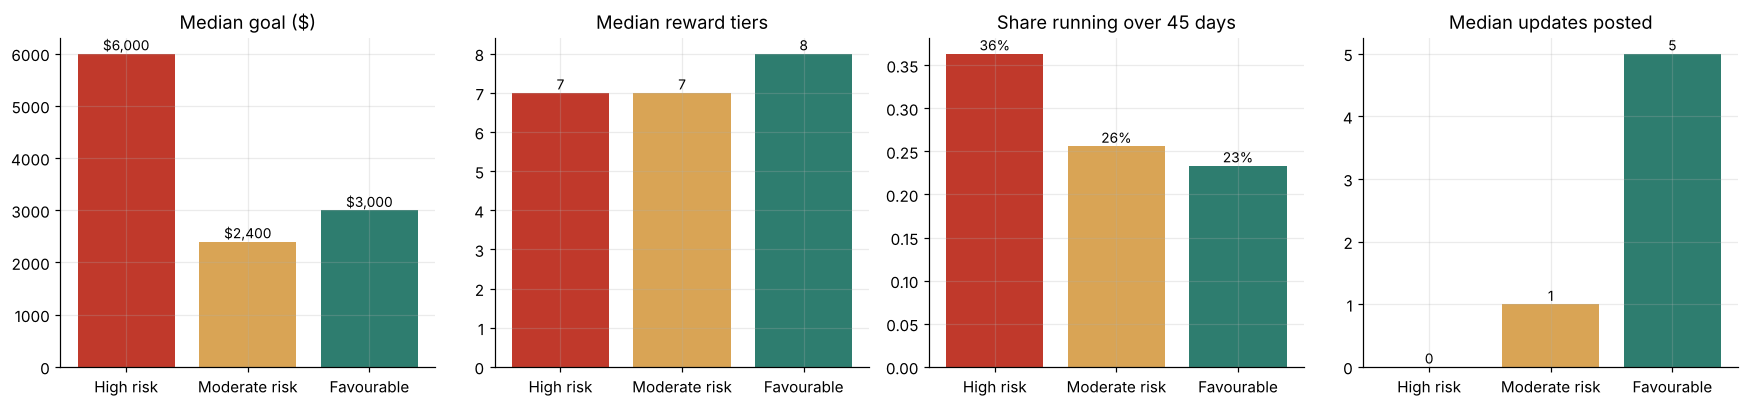

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
order = [b[1] for b in BANDS]
colors = [CORAL, SAND, TEAL]
for ax, col, title, fmt in [
    (axes[0], "median_goal", "Median goal ($)", "${:,.0f}"),
    (axes[1], "median_tiers", "Median reward tiers", "{:.0f}"),
    (axes[2], "share_over_45_days", "Share running over 45 days", "{:.0%}"),
    (axes[3], "median_updates", "Median updates posted", "{:.0f}")]:
    vals = profile.loc[order, col]
    ax.bar(order, vals, color=colors)
    ax.set_title(title)
    for i, v in enumerate(vals):
        ax.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "m4_at_risk_profile.png", dpi=130, bbox_inches="tight")
plt.show()

At-risk campaigns ask for more (median $6,000 for High risk against $3,000 for
Favourable), run longer (36% over 45 days against 23%) and more often offer
four or fewer tiers (23% against 10%). The sharpest difference is
**updates**: 74% of High-risk campaigns posted none, against 2% of Favourable
ones. Updates are an input, not a lever (§11.4), so the advice works on the
other three.

**Subcategories most often scored High risk** (at least 80 held-out
campaigns):

In [11]:
sub = tt.groupby("subcategory").agg(n=("p", "size"),
                                    high_risk_share=("band", lambda s: (s == "High risk").mean()),
                                    observed_success=("success", "mean"))
sub[sub["n"] >= 80].sort_values("high_risk_share", ascending=False).head(8).round(3)

,n,high_risk_share,observed_success
subcategory,,,
Nonfiction,151,0.556,0.377
Publishing,117,0.521,0.342
Product Design,164,0.506,0.354
Fashion,222,0.505,0.293
Children's Book,108,0.500,0.306
Film & Video,440,0.486,0.448
Video Games,136,0.463,0.360
Fiction,179,0.453,0.380


Category is not a lever, so this does not become advice. It does matter for
*framing*: a creator in a hard subcategory should be told the base rate is
low there, so that a modest predicted probability is read in context.

### 11.8 Why the advice comes from what-ifs, and from an advisor model

Two shortcuts look tempting and both fail.

**Shortcut 1: read the Logistic Regression coefficients** — "goal has a
negative coefficient, so lower it".

In [12]:
coef = pd.Series(rec.advisor.named_steps["clf"].coef_[0], index=rec.columns)
family = ["updates", "log_goal", "log_goal_per_tier", "log_goal_per_day",
          "log_goal_vs_subcat_median", "levels", "n_tiers_parsed",
          "duration_days", "is_30_day"]
coef[family].round(3).to_frame("coefficient (per std dev)")

,coefficient (per std dev)
updates,2.553
log_goal,0.682
log_goal_per_tier,-0.867
log_goal_per_day,-0.435
log_goal_vs_subcat_median,-0.569
levels,0.000
n_tiers_parsed,0.000
duration_days,-0.452
is_30_day,-0.118


`log_goal` and `log_goal_per_tier` have large coefficients with **opposite
signs**. Taken separately they say opposite things about goal. They are
nearly the same quantity — `goal_per_tier` is the goal divided by the tier
count — so the model splits one effect across several columns with offsetting
signs. `levels` and `n_tiers_parsed` are exact duplicates, so their
coefficients are arbitrary halves of one number. Individual coefficients
cannot be read as advice.

**Shortcut 2: ask the final model directly** — rebuild every goal-derived
feature, re-score with the Random Forest, and report the difference. This
answers the right question, but a forest is a sum of step functions: nudging
one input can cross a split threshold in some trees and land in a slightly
worse leaf. Measured on every held-out campaign:

In [13]:
base = rec.predict_proba(raw_test)
rows = []
for f in [0.9, 0.75, 0.5]:
    changed = rec.apply_lever(raw_test, "goal", f)
    rf_after = rec.predict_proba(changed)                     # Random Forest re-scored directly
    adv_after = rec.what_if_proba(raw_test, changed, base=base)  # advisor's effect applied to RF score
    rows.append({"change": f"goal x {f}",
                 "RF direct: share LOWERED": np.mean(rf_after < base),
                 "RF direct: mean change (pts)": (rf_after - base).mean() * 100,
                 "advisor: share lowered": np.mean(adv_after < base),
                 "advisor: mean change (pts)": (adv_after - base).mean() * 100})
whatif_cmp = pd.DataFrame(rows)
whatif_cmp.round(3)

,change,RF direct: share LOWERED,RF direct: mean change (pts),advisor: share lowered,advisor: mean change (pts)
0,goal x 0.9,0.116,1.204,0.001,1.319
1,goal x 0.75,0.072,3.397,0.001,3.610
2,goal x 0.5,0.049,7.556,0.001,8.236


Re-scored directly, the forest says that **cutting the goal makes success
less likely** for a noticeable share of campaigns — advice that contradicts
both the data (§11.5: success falls steadily as the goal rises) and itself.
On average the two approaches agree on the size of the effect; they differ in
consistency.

**The design that follows:**

- The **Random Forest scores** the campaign — the chance and the risk band
  shown to the creator come from the final model.
- The **Logistic Regression advises** — for each candidate change it
  estimates how many percentage points the change is worth, with every
  derived feature rebuilt from the raw inputs, and that change is added to
  the forest's score: `new chance = RF chance + (LR after − LR before)`.
  Its response is smooth and monotonic, so the same change always points the
  same way.
- **Why points rather than log-odds:** the forest cannot extrapolate. A
  $5,000,000 goal and a $60,000 goal land in the same leaves, so both score
  around 6%. Where the advisor sees a campaign as hopeless its points change
  is tiny, so the engine never promises a large gain to a campaign the
  forest merely cannot tell apart from a large one.

### 11.9 The approach

| Step | What it does | Where it is built |
|---|---|---|
| 1. Score | The final Random Forest predicts the chance of success from launch-time inputs plus the creator's planned number of updates; place it in a risk band with the observed rate for that range | `Recommender.assess` |
| 2. Locate | Compare goal, duration and tiers with comparable campaigns in the same subcategory | `Recommender.standing` |
| 3. What-if | Change one lever at a time, rebuild every derived feature, and estimate the effect with the advisor (its change in points, added to the RF score) | `Recommender._candidates`, `what_if_proba` |
| 4. Choose | Recommend the **mildest** change per lever that clears a 2-point gain | `MIN_GAIN` |
| 5. Combine | Apply the chosen changes together and re-estimate (effects are not simply additive) | `Assessment.plan` |
| 6. Qualify | State trade-offs and the limits of what the data can say | `Recommender._notes` |

Design commitments, each enforced in code rather than promised:

- **No outcome information.** `backers`, `pledged`, `comments` and
  `funded_percentage` have no input slot, and passing one raises an error.
- **`updates` is the creator's plan, never advice.** It is a required input
  because the final model scores with it, but no lever changes it and every
  report shows how much the chance depends on it.
- **Only changeable factors are advised.** Category and location inform the
  prediction but are never recommended.
- **Milder changes first.** A small change a creator might actually make
  beats the largest predicted gain.
- **Associations, not causes.** Every report says so.

In [14]:
cal.to_csv(REPORTS / "m4_calibration.csv")
bands.to_csv(REPORTS / "m4_risk_bands.csv", index=False)
profile.round(4).to_csv(REPORTS / "m4_at_risk_profile.csv")
corrections.to_csv(REPORTS / "m4_sept_claims_rechecked.csv", index=False)
print("Wrote m4_calibration, m4_risk_bands, m4_at_risk_profile, m4_sept_claims_rechecked")

Wrote m4_calibration, m4_risk_bands, m4_at_risk_profile, m4_sept_claims_rechecked


### Task 11 — Summary

- **Final model:** tuned Random Forest with isotonic calibration on
  `with_updates`: 81.6% accuracy against a 54.7% floor, every decile within
  4.1 points.
- **Risk bands** separate cleanly: 13.4% of High-risk campaigns succeeded,
  45.7% of Moderate and 83.8% of Favourable.
- **Three levers** — goal, duration, number of reward tiers. `updates` is a
  required input (the creator's plan) and never a lever.
- **Four September claims corrected:** the 30-day default does *not*
  outperform; "a low entry price helps" is really a tier-count effect (−23.1
  points raw, −2.4 with goal and tier count held fixed); adding a $10 tier
  does not help (it changes the prediction by −2.5 points); and location is
  **not** a modest signal (a 27-point spread across states).
- **Neither coefficients nor direct forest re-scoring make good advice.**
  Re-scored directly, the forest says a goal cut *lowers* the chance for 5–12%
  of campaigns; the advisor's estimate does so for 0.1%. The prototype scores
  with the forest and estimates what-if effects with the Logistic Regression.

**Next:** Task 12 builds and stress-tests the rules that connect predictions
to recommendations.

## Task 12 — Connecting Predictions to Recommendations

**Milestone 4 · Task 12.** Create the rules and logic that connect campaign
characteristics and model predictions to specific recommendations, making
sure every recommendation is based on the project's findings.

**How the numbers here are produced.** The chance of success comes from the
final model (calibrated Random Forest). The *effect* of a change comes from
the Logistic Regression advisor, added in percentage points to the forest's
score (`Recommender.what_if_proba`; why, in Task 11 §11.8). Every
"gain" in this notebook is measured that way.

The rules live in `src/recommend.py`. This notebook shows how each one works,
tests it across the whole held-out set, and records the decisions that came
out of that testing — including two levers that were considered and
rejected.

### 12.1 The rules in one table

Every number the advice engine relies on is a named constant at the top of
`src/recommend.py`, so a rule can be challenged and changed in one place.

In [15]:
pd.DataFrame([
    ("MIN_GAIN", f"{MIN_GAIN:.0%}", "Smallest predicted gain worth recommending. Held-out calibration is within a few points in every decile, so smaller gains sit inside the noise."),
    ("GOAL_FACTORS", str(GOAL_FACTORS), "Candidate goals as a fraction of the current one, mildest first. Never below half."),
    ("GOAL_FLOOR_QUANTILE", f"{GOAL_FLOOR_QUANTILE:.0%}", "A suggested goal never falls below this quantile of the subcategory's goals."),
    ("DURATION_TARGETS", f"{DURATION_TARGETS} days", "Candidate durations, only offered to campaigns running past the default. Never 30."),
    ("DEFAULT_DURATION", str(DEFAULT_DURATION), "The platform default window. No advice is given from or to it (see 12.5)."),
    ("TIER_TARGETS", str(TIER_TARGETS), "Candidate total numbers of reward tiers."),
    ("MIN_TIER_ADDITION", str(MIN_TIER_ADDITION), "A tier candidate must add at least this many tiers. Testing showed \"add a tenth tier\" to someone with nine is noise, not advice."),
    ("BANDS", str([(f'<{u:.0%}', n) for u, n in BANDS]), "Risk bands by predicted probability."),
], columns=["constant", "value", "what it does"])

,constant,value,what it does
0,MIN_GAIN,2%,Smallest predicted gain worth recommending. Held-out calibration is within a few point...
1,GOAL_FACTORS,"[0.9, 0.75, 0.6, 0.5]","Candidate goals as a fraction of the current one, mildest first. Never below half."
2,GOAL_FLOOR_QUANTILE,10%,A suggested goal never falls below this quantile of the subcategory's goals.
3,DURATION_TARGETS,"[45, 35, 28] days","Candidate durations, only offered to campaigns running past the default. Never 30."
4,DEFAULT_DURATION,"(29.5, 30.5)",The platform default window. No advice is given from or to it (see 12.5).
5,TIER_TARGETS,"[6, 8, 10]",Candidate total numbers of reward tiers.
6,MIN_TIER_ADDITION,2,"A tier candidate must add at least this many tiers. Testing showed ""add a tenth tier"" ..."
7,BANDS,"[('<35%', 'High risk'), ('<55%', 'Moderate risk'), ('<101%', 'Favourable')]",Risk bands by predicted probability.


The selection rule: for each lever, recommend the **mildest candidate that
clears `MIN_GAIN`**. Showing every candidate alongside lets the creator see
the whole trade-off, but the headline advice is the smallest change that
moves the needle — the one most likely to actually be made.

### 12.2 Features are rebuilt from raw inputs, never patched

Changing the goal does not change one number. It changes every feature that
is derived from it. Patching a single column would leave the others
describing the old goal.

In [16]:
camp = dict(goal=40000, duration=45, reward_tiers=[10, 25, 50],
            category="Film & Video", subcategory="Documentary", state="CA", updates=5)
c_before = rec.validate(camp)
c_after = rec.validate({**camp, "goal": 20000})
X1 = rec.featurize(rec.to_raw([c_before])).iloc[0]
X2 = rec.featurize(rec.to_raw([c_after])).iloc[0]
changed = pd.DataFrame({"goal $40,000": X1, "goal $20,000": X2})
changed = changed[changed.iloc[:, 0] != changed.iloc[:, 1]]
print(f"Halving the goal changed {len(changed)} of {len(X1)} model features:\n")
changed.round(3)

Halving the goal changed 5 of 138 model features:



,"goal $40,000","goal $20,000"
log_goal,10.597,9.904
log_goal_per_day,6.791,6.099
min_tier_pct_of_goal,0.000,0.000
log_goal_per_tier,9.498,8.805
log_goal_vs_subcat_median,1.792,1.253


Each of those is a goal-derived feature (goal per day, goal per tier, goal
relative to the subcategory median, entry price as a share of the goal).
Re-running the whole feature pipeline for every what-if keeps them
consistent. A test proves the rebuild matches the training matrix exactly:

In [17]:
check = rec.self_check()
check

{'rows_checked': 2000,
 'max_abs_difference': 0.0,
 'matrix_reproduced': True,
 'tier_round_trip_ok': True}

`max_abs_difference` of zero means that re-featurising 2,000 training
campaigns from their raw inputs reproduces the model's training matrix
exactly, so the what-if engine is asking the model the same question it was
trained on.

### 12.3 How each lever behaves across the held-out set

Each candidate change is applied to every eligible held-out campaign and the
change in predicted probability recorded. This is the test of whether a rule
is *systematically* sensible rather than sensible for one example.

In [18]:
def effect(lever, value, rows):
    """Change in predicted chance, in points, from applying one lever to `rows`."""
    before = rec.predict_proba(rows)
    after = rec.what_if_proba(rows, rec.apply_lever(rows, lever, value), base=before)
    return (after - before) * 100

records = []
def record(lever, label, gains):
    records.append({"lever": lever, "change": label, "campaigns": len(gains),
                    "mean gain (pts)": gains.mean(), "median gain (pts)": np.median(gains),
                    "share raised": float(np.mean(gains > 0)),
                    "share clearing MIN_GAIN": float(np.mean(gains >= MIN_GAIN * 100))})

for f in GOAL_FACTORS:
    record("goal", f"goal x {f}", effect("goal", f, raw_test))

dur = raw_test["duration"]
for target in sorted(DURATION_TARGETS, reverse=True):
    rows = raw_test[(dur > DEFAULT_DURATION[1]) & (dur <= 60) & (dur > target + 0.5)]
    record("duration", f"shorten to {target} days", effect("duration", target, rows))

for target in TIER_TARGETS:
    rows = raw_test[raw_test["levels"] <= target - MIN_TIER_ADDITION]
    rows = rows.sample(min(2500, len(rows)), random_state=0)
    record("reward tiers", f"{target} tiers", effect("reward tiers", target, rows))

lever_table = pd.DataFrame(records)
lever_table.round(3)

,lever,change,campaigns,mean gain (pts),median gain (pts),share raised,share clearing MIN_GAIN
0,goal,goal x 0.9,7676,1.319,1.277,0.999,0.237
1,goal,goal x 0.75,7676,3.610,3.571,0.999,0.703
2,goal,goal x 0.6,7676,6.213,6.205,0.999,0.801
3,goal,goal x 0.5,7676,8.236,8.183,0.999,0.834
4,duration,shorten to 45 days,1247,2.751,2.060,1.000,0.510
5,duration,shorten to 35 days,2505,3.313,2.191,1.000,0.534
6,duration,shorten to 28 days,3287,3.802,2.542,1.000,0.560
7,reward tiers,6 tiers,1211,8.436,6.467,1.000,0.846
8,reward tiers,8 tiers,2500,7.047,4.882,1.000,0.811
9,reward tiers,10 tiers,2500,6.752,4.768,1.000,0.777


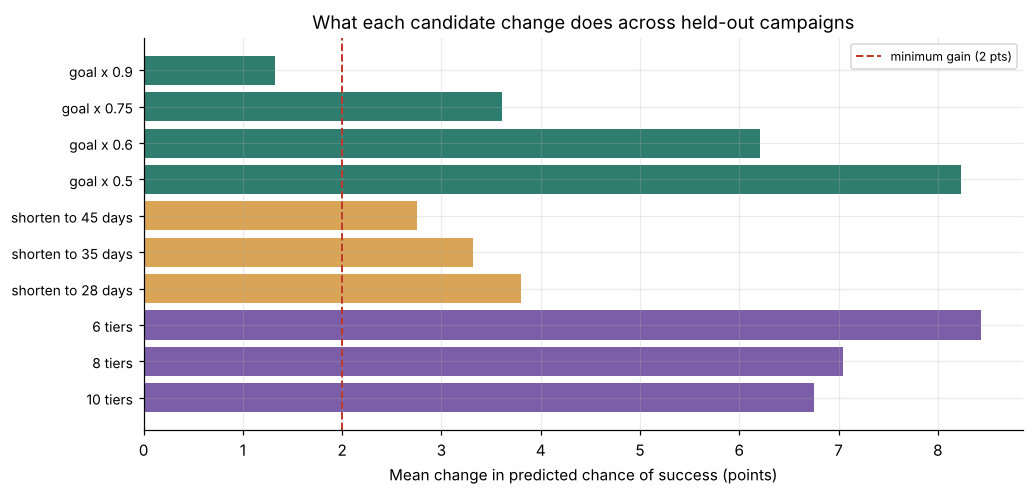

In [19]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
colors = {"goal": TEAL, "duration": SAND, "reward tiers": PLUM}
ax.barh(range(len(lever_table)), lever_table["mean gain (pts)"],
        color=[colors[l] for l in lever_table["lever"]])
ax.axvline(MIN_GAIN * 100, color=CORAL, ls="--", lw=1.3, label=f"minimum gain ({MIN_GAIN * 100:.0f} pts)")
ax.set_yticks(range(len(lever_table)))
ax.set_yticklabels(lever_table["change"], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Mean change in predicted chance of success (points)")
ax.set_title("What each candidate change does across held-out campaigns")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m4_lever_response.png", dpi=130, bbox_inches="tight")
plt.show()

**Reading it.**

- **Every lever raises the predicted chance** for at least 99.9% of the
  campaigns it applies to.
- **Reward tiers and larger goal cuts move it most.** Offering 6 tiers adds
  8.4 points on average for campaigns that can add at least two; halving the
  goal adds 8.2. A 25% goal cut adds 3.6, and shortening a long campaign 2.8
  to 3.8.
- These effects hold the creator's planned updates fixed. `updates` carries
  much of the signal, so the levers move the chance less than it does.
- **Why the mildest goal cut is usually 25%:** a 10% cut clears the 2-point
  bar for about one campaign in four (23.7%).

### 12.4 The "mildest change" rule on one campaign

All candidates are shown, the mildest that clears the minimum gain is
marked, and that is the one that goes into the combined plan.

In [20]:
a = rec.assess(camp)
a.options.assign(probability=lambda d: d.probability.map("{:.1%}".format),
                 gain_pp=lambda d: d.gain_pp.round(1),
                 funding_floor=lambda d: d.funding_floor.map("${:,.0f}".format))[
    ["lever", "change", "probability", "gain_pp", "recommended"]]

,lever,change,probability,gain_pp,recommended
0,goal,"Lower the goal to $36,000",15.9%,1.8,False
1,goal,"Lower the goal to $30,000",19.4%,5.3,True
2,goal,"Lower the goal to $24,000",24.2%,10.2,False
3,goal,"Lower the goal to $20,000",28.6%,14.5,False
4,duration,Shorten the campaign to 35 days,16.4%,2.4,True
5,duration,Shorten the campaign to 28 days,18.0%,3.9,False
6,reward tiers,"Offer 6 reward tiers ($10,$15,$20,$25,$40,$50)",21.4%,7.4,True
7,reward tiers,"Offer 8 reward tiers ($10,$15,$20,$25,$30,$40,$50,$100)",26.3%,12.2,False
8,reward tiers,"Offer 10 reward tiers ($10,$15,$20,$25,$30,$40,$50,$60,$75,$100)",29.5%,15.4,False


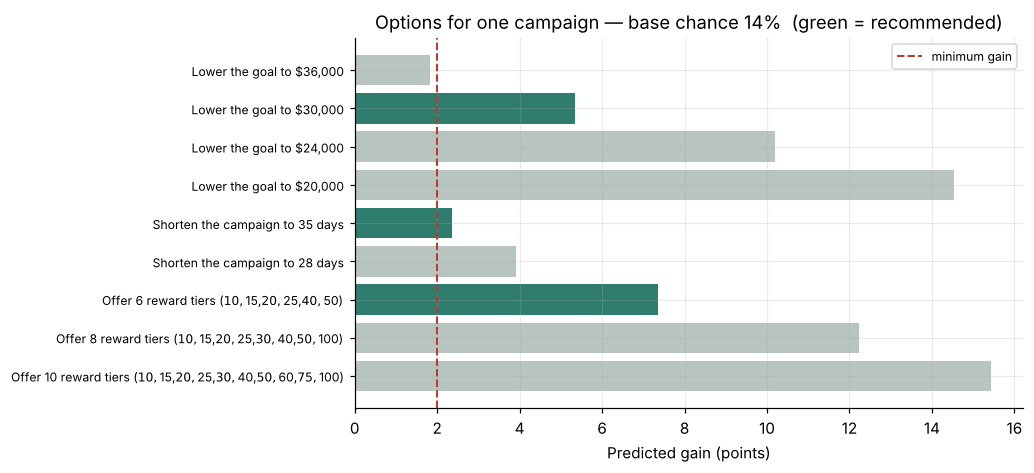


Combined plan: 14.1% -> 32.1%
  - Lower the goal to $30,000
  - Shorten the campaign to 35 days
  - Offer 6 reward tiers ($10,$15,$20,$25,$40,$50)


In [21]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))
o = a.options
ax.barh(range(len(o)), o["gain_pp"],
        color=[TEAL if r else "#B8C4C0" for r in o["recommended"]])
ax.axvline(MIN_GAIN * 100, color=CORAL, ls="--", lw=1.3, label="minimum gain")
ax.set_yticks(range(len(o))); ax.set_yticklabels(o["change"], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("Predicted gain (points)")
ax.set_title(f"Options for one campaign — base chance {a.probability:.0%}  (green = recommended)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m4_example_options.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"\nCombined plan: {a.probability:.1%} -> {a.plan['probability']:.1%}")
for ch in a.plan["changes"]:
    print("  -", ch)

### 12.5 Why exactly 30 days is never a source or target of advice

September's notebook said the 30-day default *outperforms*. It does not. The
question here is what to do about the dip, since advice like "run 28 days
instead of 30" would be a gimmick if the dip is not caused by the length.

In [22]:
t = train.copy()
t["dur_b"] = pd.cut(t["duration_days"], [0, 25, 29.5, 30.5, 35, 45, 60, 100],
                    labels=["<=25", "26-29", "30 (default)", "31-35", "36-45", "46-60", ">60"])
dur_tbl = t.groupby("dur_b", observed=True)["success"].agg(["mean", "size"])
dur_tbl.columns = ["success_rate", "campaigns"]
print(dur_tbl.round(3).to_string())

              success_rate  campaigns
dur_b                                
<=25                 0.685       3631
26-29                0.702       1112
30 (default)         0.530       9288
31-35                0.636       3045
36-45                0.554       4882
46-60                0.473       5327
>60                  0.426       3417


In [23]:
# What does the MODEL do with a one-day change across the default?
_b = rec.predict_proba(raw_test)
def _at(days):
    return rec.what_if_proba(raw_test, rec.apply_lever(raw_test, "duration", days), base=_b)
p30, p29, p31, p35, p28 = _at(30), _at(29), _at(31), _at(35), _at(28)
print(f"29 days vs 30 days: {(p29 - p30).mean() * 100:+.1f} points on average")
print(f"31 days vs 30 days: {(p31 - p30).mean() * 100:+.1f} points on average")
print(f"28 days vs 30 days: {(p28 - p30).mean() * 100:+.1f} points on average")
print(f"35 days vs 30 days: {(p35 - p30).mean() * 100:+.1f} points on average")

29 days vs 30 days: +3.7 points on average
31 days vs 30 days: +3.4 points on average
28 days vs 30 days: +3.9 points on average
35 days vs 30 days: +2.5 points on average


**What this shows.** Campaigns left at exactly 30 days succeeded at a clearly
lower rate than the 26-29 and 31-35 day groups on either side — and the
model reproduces that: moving *one day* either way changes its prediction by
about **3.4 to 3.7 points**.

One day of campaign length cannot plausibly do that. The model is reacting
to the "is exactly 30 days" flag, which marks campaigns whose creators left
the platform default untouched. That is a statement about who accepts
defaults — likely creators who planned less — not about what 30 days does.
Advice such as "run 28 days instead of 30" would promise a gain the creator
cannot buy by changing a number.

**Decision:** the engine never recommends a duration from or to the 30-day
window, and says so in the report. The shortening advice it does give applies
only to campaigns running *past* the default, where the pattern is a smooth
decline rather than a one-day cliff.

### 12.6 Entry price: considered and rejected

Two questions. Does the model respond to a cheaper entry tier? And is the
response about the *price* of the added tier or just the extra tier?

In [24]:
tiers = raw_test["reward_levels"].map(string_to_tiers)
base_all = rec.predict_proba(raw_test)

def with_added(tier_fn, mask):
    new = [tiers_to_string(sorted(set(x + [tier_fn(x)]))) if m else s
           for x, s, m in zip(tiers, raw_test["reward_levels"], mask)]
    r = raw_test.copy()
    r["reward_levels"] = new
    r["levels"] = [len(string_to_tiers(v)) for v in new]
    return (rec.what_if_proba(raw_test, r, base=base_all) - base_all) * 100

entry = tiers.map(min)
rows = []
for label, mask in [("entry $11-25", entry.between(10.01, 25).to_numpy()),
                    ("entry above $25", entry.gt(25).to_numpy())]:
    g = with_added(lambda x: 10.0, mask)
    rows.append({"campaigns": label, "n": int(mask.sum()),
                 "add a $10 tier: mean gain (pts)": g[mask].mean(),
                 "share raised": float(np.mean(g[mask] > 0))})
pd.DataFrame(rows).round(2)

,campaigns,n,add a $10 tier: mean gain (pts),share raised
0,entry $11-25,837,-0.29,0.33
1,entry above $25,139,-2.51,0.09


In [25]:
# Same campaigns, same number of added tiers -- cheap tier vs expensive tier.
mask = tiers.map(len).between(2, 8).to_numpy()
cheap = with_added(lambda x: 10.0 if 10.0 not in x else 15.0, mask)
top = with_added(lambda x: float(min((a for a in NICE_AMOUNTS if a >= 2 * max(x)), default=2 * max(x))), mask)
print(f"Campaigns with 2-8 tiers: {mask.sum():,}")
print(f"Add a CHEAP tier ($10):            {cheap[mask].mean():+.2f} points on average")
print(f"Add an EXPENSIVE tier (2x the top): {top[mask].mean():+.2f} points on average")

Campaigns with 2-8 tiers: 4,597
Add a CHEAP tier ($10):            +1.15 points on average
Add an EXPENSIVE tier (2x the top): +1.98 points on average


**What this shows.**

- Adding a $10 tier to campaigns whose cheapest reward is above $25
  **lowers** the prediction by about 2.5 points on average (it rises for only
  9% of them); for $11–25 entries the change is −0.3 points. A cheaper entry
  price does not help.
- Adding an expensive top-end tier does **better** than adding a cheap one
  (+2.0 against +1.2 points).

So the model responds to the *number* of tiers, not to how cheap the
cheapest one is. That agrees with Task 11, where the entry-price gap
shrank to a few points once goal size and tier count were held fixed.

**Decision:** there is no entry-price lever. The tier lever speaks only of
the number of tiers, and the report explains why a high entry price is not
the thing to fix.

### 12.7 Suggested tiers look like tiers a creator would offer

New tiers fill the widest price gaps (measured in log-price) and snap to
believable amounts. If there is no room left between the extremes, a
higher-priced tier is added instead of cramming in $12, $13, $15.

In [26]:
examples = [[5, 25, 100], [10, 25], [25], [5, 500], [1, 2], [5, 25, 50]]
pd.DataFrame([{"current tiers": tiers_to_string(e), "target": n,
               "suggested": tiers_to_string(suggest_tiers(e, n)),
               "result count": len(suggest_tiers(e, n))}
              for e, n in [(e, 8) for e in examples]])

,current tiers,target,suggested,result count
0,"$5,$25,$100",8,"$5,$10,$15,$25,$40,$50,$75,$100",8
1,"$10,$25",8,"$10,$15,$20,$25,$30,$40,$50,$100",8
2,$25,8,"$25,$40,$50,$75,$100,$150,$250,$500",8
3,"$5,$500",8,"$5,$10,$15,$25,$50,$150,$250,$500",8
4,"$1,$2",8,"$1,$2,$3,$5,$10,$15,$20,$40",8
5,"$5,$25,$50",8,"$5,$10,$15,$20,$25,$30,$40,$50",8


### 12.8 Why the plan is re-predicted, not added up

Goal, duration and tiers interact: the goal-per-day and goal-per-tier
features each involve two levers at once. So the combined effect is not the
sum of the individual effects, and the plan is always a fresh prediction.

In [27]:
at_risk = test[rec.holdout_p < BANDS[1][0]]
at_risk = at_risk[at_risk["duration_days"] <= 60].sample(200, random_state=1)
from src.recommend import campaign_from_row

gaps = []
for _, row in at_risk.iterrows():
    res = rec.assess(campaign_from_row(row))
    if res.plan is not None and res.options["recommended"].sum() > 1:
        individual = res.options.loc[res.options["recommended"], "gain_pp"].sum()
        gaps.append({"sum of individual gains": individual,
                     "actual combined gain": res.plan["gain_pp"]})
gaps = pd.DataFrame(gaps)
gaps["combined minus sum"] = gaps["actual combined gain"] - gaps["sum of individual gains"]
print(f"{len(gaps)} campaigns with two or more recommendations")
gaps.describe().loc[["mean", "50%", "min", "max"]].round(2)

139 campaigns with two or more recommendations


,sum of individual gains,actual combined gain,combined minus sum
mean,9.70,10.35,0.65
50%,8.54,9.09,0.42
min,4.15,4.49,-1.36
max,37.19,39.23,5.48


**What this shows.** On average the combined gain is close to the sum of the
individual gains (10.4 against 9.7 points across 139 campaigns), so the
interaction is usually small. But for individual campaigns they differ by as
much as 5.5 points in one direction and 1.4 in the other — the goal-per-day and
goal-per-tier features each involve two levers at once, and probabilities
are not additive near the extremes.

That is enough to justify the rule: **the plan is always a fresh
prediction**, never a sum shown to the creator.

### 12.9 Save

In [28]:
lever_table.round(4).to_csv(REPORTS / "m4_lever_effects.csv", index=False)
dur_tbl.round(4).to_csv(REPORTS / "m4_duration_buckets.csv")
print("Wrote m4_lever_effects.csv, m4_duration_buckets.csv")

Wrote m4_lever_effects.csv, m4_duration_buckets.csv


### Task 12 — Summary

#### Decisions made in this task

| Decision | Basis |
|---|---|
| Three levers only: goal, duration (past the default only), number of reward tiers | The only controllable factors with real signal (Task 11) |
| `updates` is an input, never a lever | The final model needs it; part of its effect is reverse causation |
| Recommend the **mildest** candidate clearing 2 points | Small changes get made; a 10% goal cut clears the bar for about one campaign in four, so the usual cut is 25% |
| Never advise from or to exactly 30 days | A one-day move across the default shifts the prediction by 3.4–3.7 points: the "left at default" flag, not the duration |
| **No entry-price lever** | Adding a $10 tier to a >$25 entry lowers the prediction by about 2.5 points |
| Tier lever is about *count* | An expensive added tier does better than a cheap one (+2.0 against +1.2 points) |
| Features rebuilt from raw inputs | The rebuild reproduces the training matrix exactly (§12.2) |
| Goal roundness held fixed in what-ifs | Found in Task 15 (Task 14, row 18) |
| Combined plan is re-estimated as one change | Close to the sum on average, but differs by up to 5.5 points for some campaigns |

#### Honest limits of the rules

- **Reward tiers is the strongest lever and the most exposed to selection.**
  Creators who build many tiers probably planned the campaign more carefully.
  The report says so beside any tier advice.
- **Predicted gains are associations.** They describe how campaigns with those
  characteristics fared, not what changing one characteristic would cause.

**Next:** Task 13 packages these rules into a reusable function.

## Task 13 — The Recommendation Prototype

**Milestone 4 · Task 13.** An initial prototype that takes campaign
information and returns a predicted outcome with useful recommendations.

The prototype is a single reusable call:

```python
from src.recommend import get_recommender
rec = get_recommender("..")
print(rec.report(my_campaign))
```

Everything underneath — the final Random Forest that scores the campaign,
the Logistic Regression advisor that estimates what each change is worth, the
feature pipeline and the what-if rules — lives in `src/recommend.py`. This notebook is the
**front end**: describe a campaign, get a report.

**To try your own campaign, edit the dictionary in §13.1 and re-run.**

### 13.1 Describe a campaign and get a report

**Edit this cell.** Only things a creator knows before pressing publish are
accepted, including how many updates they plan to post.

In [29]:
my_campaign = dict(
    goal=40000,                                   # dollars
    duration=60,                                  # days, 1 to 60
    reward_tiers=[10, 25, 50],                    # the price of each reward tier
    category="Film & Video",
    subcategory="Documentary",
    state="CA",                                   # two-letter code
    updates=5,                                    # updates you PLAN to post during the campaign
    # Optional - leave out if unknown:
    # city="Los Angeles",
    # name="My project title",
    # launch_date="2012-03-01",
)

print(rec.report(my_campaign))

CAMPAIGN ASSESSMENT
  Film & Video / Documentary - CA - goal $40,000 - 60 days - 3 reward tiers ($10,$25,$50) - 5 planned updates

Predicted chance of reaching the goal: 13%   [High risk]   (final model: Random Forest (tuned + calibrated))
  Held-out campaigns scored 8%-18% actually succeeded 11% of the time (n=664).

Where you stand (Documentary, 2,442 campaigns)
  Goal: $40,000 is at the 91st percentile (median $8,000).
  Campaigns with a similar goal (half to double yours): 34% succeeded (n=523).
  Successful campaigns here typically ran 35 days with 8 reward tiers and posted 6 updates.

What you could change (estimated effect on your chance)
  [goal        ] Lower the goal to $36,000: 14% (+1.5 pts)
  [goal        ] Lower the goal to $30,000: 17% (+4.4 pts)  <- recommended
  [goal        ] Lower the goal to $24,000: 21% (+8.5 pts)
  [goal        ] Lower the goal to $20,000: 25% (+12.3 pts)
  [duration    ] Shorten the campaign to 45 days: 16% (+3.4 pts)  <- recommended
  [duration 

### 13.2 What goes in

| Field | Required | Notes |
|---|---|---|
| `goal` | yes | Funding target in dollars. Must be positive. |
| `duration` | yes | Campaign length in days, from 1 to 60 (Kickstarter's maximum). |
| `reward_tiers` | yes | A list of reward prices, e.g. `[5, 25, 100]`. The *number* of tiers matters as much as the prices. |
| `category` | yes | One of the 13 categories (see §13.3). |
| `subcategory` | yes | Must belong to the chosen category. |
| `state` | yes | Two-letter US state code. |
| `updates` | yes | The number of updates the creator **plans** to post during the campaign, 0 or more. The model leans on it heavily (see §13.7); it is used as given and never recommended. |
| `city` | no | If omitted, the typical value from the training data is used (not zero). **Supplying it can shift the chance by several points** - see §13.6. |
| `name` | no | Project title. A weak signal; if omitted, typical values are used. |
| `launch_date` | no | If omitted, the latest period in the training data is used. |

### What deliberately cannot go in

`backers`, `pledged`, `comments` and `funded_percentage` are outcomes that do
not exist at launch, and the prototype **refuses them** rather than ignoring
them (§13.5). It cannot use information it is not given a slot for.

### 13.3 Valid categories and subcategories

In [30]:
pd.DataFrame([{"category": c, "subcategories": ", ".join(s)}
              for c, s in rec.taxonomy.items()])

,category,subcategories
0,Art,"Art, Conceptual Art, Digital Art, Illustration, Mixed Media, Painting, Performance Art..."
1,Comics,Comics
2,Dance,Dance
3,Design,"Crafts, Design, Graphic Design, Product Design"
4,Fashion,Fashion
5,Film & Video,"Animation, Documentary, Film & Video, Narrative Film, Short Film, Webseries"
6,Food,Food
7,Games,"Board & Card Games, Games, Video Games"
8,Music,"Classical Music, Country & Folk, Electronic Music, Hip-Hop, Indie Rock, Jazz, Music, P..."
9,Photography,Photography


Several categories have a subcategory with the same name as the category
itself (`Dance / Dance`, `Film & Video / Film & Video`). That is how the
source data records campaigns filed under a category without a more
specific subcategory, and it is a valid choice.

### 13.4 Using the result in code

`rec.report(...)` returns formatted text. `rec.assess(...)` returns the
underlying object, for when the numbers are needed rather than the prose.

In [31]:
a = rec.assess(my_campaign)
print(f"Predicted chance:  {a.probability:.1%}")
print(f"Risk band:         {a.band}")
if a.local_info:
    print(f"Held-out campaigns scored {a.local_info['low']:.0%}-{a.local_info['high']:.0%} "
          f"actually succeeded {a.local_info['rate']:.0%} of the time "
          f"(n={a.local_info['n']:,})")

Predicted chance:  12.8%
Risk band:         High risk
Held-out campaigns scored 8%-18% actually succeeded 11% of the time (n=664)


In [32]:
# Every option the engine considered, with its predicted effect.
a.options.assign(
    probability=lambda d: (d.probability * 100).round(1),
    gain_pp=lambda d: d.gain_pp.round(1),
    funding_floor=lambda d: d.funding_floor.round(0),
)[["lever", "change", "probability", "gain_pp", "funding_floor", "recommended"]]

,lever,change,probability,gain_pp,funding_floor,recommended
0,goal,"Lower the goal to $36,000",14.3,1.5,5132.0,False
1,goal,"Lower the goal to $30,000",17.2,4.4,5148.0,True
2,goal,"Lower the goal to $24,000",21.3,8.5,5101.0,False
3,goal,"Lower the goal to $20,000",25.0,12.3,5003.0,False
4,duration,Shorten the campaign to 45 days,16.1,3.4,6459.0,True
5,duration,Shorten the campaign to 35 days,18.5,5.7,7400.0,False
6,duration,Shorten the campaign to 28 days,20.0,7.3,8019.0,False
7,reward tiers,"Offer 6 reward tiers ($10,$15,$20,$25,$40,$50)",18.9,6.1,7543.0,True
8,reward tiers,"Offer 8 reward tiers ($10,$15,$20,$25,$30,$40,$50,$100)",23.0,10.3,9208.0,False
9,reward tiers,"Offer 10 reward tiers ($10,$15,$20,$25,$30,$40,$50,$60,$75,$100)",25.8,13.1,10326.0,False


In [33]:
# The combined plan, as a campaign description you can feed straight back in.
if a.plan:
    print(f"Plan: {a.probability:.1%} -> {a.plan['probability']:.1%}")
    for k in ("goal", "duration", "reward_tiers"):
        print(f"  {k:13s} {my_campaign[k]!s:28.28} -> {a.plan['campaign'][k]!s:.60}")
    direct = rec.probability(a.plan['campaign'])
    print(f"\nPlan estimate (RF score + advisor's effect): {a.plan['probability']:.1%}")
    print(f"Random Forest re-scoring the planned campaign directly: {direct:.1%}")

Plan: 12.8% -> 30.5%
  goal          40000                        -> 30000.0
  duration      60                           -> 45.0
  reward_tiers  [10, 25, 50]                 -> [10.0, 15.0, 20.0, 25.0, 40.0, 50.0]

Plan estimate (RF score + advisor's effect): 30.5%
Random Forest re-scoring the planned campaign directly: 18.4%


**Why two numbers can differ.** The plan estimate starts from the Random
Forest's score and adds the advisor's estimate of what the changes are worth.
Re-scoring the changed campaign directly with the forest can give a different
figure, especially for campaigns far from typical (here: a $40,000, 60-day
documentary with three tiers, in the top tenth of goals). Forests flatten out
in sparse regions of the data, so they often under-react to changes there.
The data itself (Task 11 §11.5) shows large-goal campaigns with more
tiers succeeding several times as often as those with few, which is the
direction the advisor follows. How often and how far the two disagree is
measured on 250 real campaigns in Task 15 §15.7.

### 13.5 What the prototype refuses

Bad input produces a specific, actionable message rather than a wrong answer
or a stack trace.

In [34]:
bad_inputs = {
    "no planned updates given": {k: v for k, v in my_campaign.items() if k != "updates"},
    "negative planned updates": {**my_campaign, "updates": -3},
    "includes backers (not known at launch)": {**my_campaign, "backers": 300},
    "duration over Kickstarter's 60-day limit": {**my_campaign, "duration": 90},
    "negative goal": {**my_campaign, "goal": -500},
    "subcategory not in the category": {**my_campaign, "subcategory": "Jazz"},
    "unknown state code": {**my_campaign, "state": "ZZ"},
    "missing reward tiers": {k: v for k, v in my_campaign.items() if k != "reward_tiers"},
}
for label, c in bad_inputs.items():
    try:
        rec.probability(c)
        print(f"NOT REFUSED  {label}")
    except ValueError as e:
        print(f"refused  {label}\n         -> {str(e)[:150]}\n")

refused  no planned updates given
         -> Missing required fields: ['updates']

refused  negative planned updates
         -> updates (the number you plan to post) cannot be negative

refused  includes backers (not known at launch)
         -> ['backers'] cannot be used: they are outcomes, only known after a campaign ends. Describe the campaign as planned instead.

refused  duration over Kickstarter's 60-day limit
         -> duration must be between 1 and 60 days (Kickstarter's current maximum)

refused  negative goal
         -> goal must be positive

refused  subcategory not in the category
         -> 'Jazz' is not a subcategory of 'Film & Video'. Choose from: ['Animation', 'Documentary', 'Film & Video', 'Narrative Film', 'Short Film', 'Webseries']

refused  unknown state code
         -> Unknown state 'ZZ'. Use a two-letter code.

refused  missing reward tiers
         -> Missing required fields: ['reward_tiers']



### 13.6 How much do the optional fields matter?

City, title and launch date are optional because a creator may not want to
supply them. But "optional" is not the same as "irrelevant", so measure it:
for every held-out campaign, compare the prediction with the real value
against the prediction with the field left out.

In [35]:
raw = test[RAW_COLUMNS].copy()
with_all = rec.predict_proba(raw)

def effect_of_omitting(label, **blank):
    r = raw.copy()
    for k, v in blank.items():
        r[k] = v
    d = np.abs(rec.predict_proba(r) - with_all) * 100
    return {"field left out": label, "mean change (pts)": d.mean(),
            "90th percentile (pts)": np.percentile(d, 90), "largest (pts)": d.max()}

omit = pd.DataFrame([
    effect_of_omitting("city", city=None),
    effect_of_omitting("title", name=None),
    effect_of_omitting("launch date", launch_date=rec.default_launch_date),
    effect_of_omitting("all three", city=None, name=None,
                       launch_date=rec.default_launch_date),
])
omit.round(1)

,field left out,mean change (pts),90th percentile (pts),largest (pts)
0,city,2.9,8.1,30.7
1,title,1.2,3.3,15.2
2,launch date,0.9,2.6,13.0
3,all three,3.4,9.0,31.5


**City is not negligible.** Leaving it out shifts a typical prediction by
about 3 points (8 at the 90th percentile, 31 at the most). The title and launch date matter
much less. So: **supply the city when it is known** — the probability is
noticeably better informed with it.

Does it also change the *advice*? Every what-if holds city, title and date
fixed, so the recommended changes should mostly survive. Test it on real
campaigns, with and without those three fields:

In [36]:
sample = test[test["duration_days"] <= 60].sample(200, random_state=7)
same = 0
plan_diff = []
for _, row in sample.iterrows():
    full_c = campaign_from_row(row)
    bare_c = {k: v for k, v in full_c.items() if k not in ("city", "name", "launch_date")}
    a_full, a_bare = rec.assess(full_c), rec.assess(bare_c)
    r_full = set(a_full.options.loc[a_full.options["recommended"], "change"])
    r_bare = set(a_bare.options.loc[a_bare.options["recommended"], "change"])
    same += r_full == r_bare
    plan_diff.append(abs((a_full.plan["gain_pp"] if a_full.plan else 0.0)
                         - (a_bare.plan["gain_pp"] if a_bare.plan else 0.0)))

print(f"Campaigns tested:                         {len(sample)}")
print(f"Identical recommended changes:            {same / len(sample):.0%}")
print(f"Plan gain differs by (mean / 90th / max): "
      f"{np.mean(plan_diff):.1f} / {np.percentile(plan_diff, 90):.1f} / {np.max(plan_diff):.1f} points")

Campaigns tested:                         200
Identical recommended changes:            74%
Plan gain differs by (mean / 90th / max): 1.1 / 3.1 / 16.5 points


The advice is **largely but not completely** insensitive to the optional
fields. Most campaigns get the same recommendations either way; the starting
probability is what moves. A borderline option can cross the 2-point
threshold when the baseline shifts, because the same change in odds is worth
slightly different points at different starting probabilities.

(September's notebooks called location a modest signal. That was wrong, for
the state and the city alike: see Task 11 section 11.6.)

### 13.7 How much does the planned number of updates matter?

`updates` is the input the final model leans on most, and before launch it is
only a plan. For every held-out campaign, compare the chance using its actual
update count with the chance at a few fixed plans.

In [37]:
base_upd = rec.predict_proba(raw)
rows = [{"updates entered": "actual count (as scored)", "mean chance": base_upd.mean(),
         "mean change vs actual (pts)": 0.0}]
for u in [0, 2, 5, 10]:
    p_u = rec.predict_proba(raw.assign(updates=float(u)))
    rows.append({"updates entered": f"{u} for every campaign", "mean chance": p_u.mean(),
                 "mean change vs actual (pts)": (np.abs(p_u - base_upd) * 100).mean()})
upd_sens = pd.DataFrame(rows)
print(f"Held-out campaigns: {len(raw):,}; median actual updates {raw['updates'].median():.0f}")
upd_sens.round(3)

Held-out campaigns: 7,676; median actual updates 2


,updates entered,mean chance,mean change vs actual (pts)
0,actual count (as scored),0.549,0.000
1,0 for every campaign,0.218,33.080
2,2 for every campaign,0.588,24.089
3,5 for every campaign,0.777,27.559
4,10 for every campaign,0.867,32.301


**The plan matters more than anything else a creator types in.** Entering 0
updates for every held-out campaign lowers the average chance from 55% to 22%;
entering 5 raises it to 78%. Depending on the plan, a campaign's chance moves
by 24–33 points on average, against about 3 points for leaving out the city.
This is why `updates` is required rather than filled in with a typical value,
and why every report prints the chance with no updates beside the planned one.

### 13.8 Scoring several campaigns at once

`summary_frame` takes a dictionary of named campaigns and returns one row
each — useful for comparing alternatives before committing to one.

In [38]:
options = {
    "As planned": my_campaign,
    "Smaller goal": {**my_campaign, "goal": 25000},
    "Shorter": {**my_campaign, "duration": 35},
    "More reward tiers": {**my_campaign, "reward_tiers": [10, 15, 25, 40, 50, 100, 250]},
    "All three": {**my_campaign, "goal": 25000, "duration": 35,
                  "reward_tiers": [10, 15, 25, 40, 50, 100, 250]},
}
summary = rec.summary_frame(options)
summary.assign(chance=(summary.chance * 100).round(1),
               **{"plan chance": (summary["plan chance"] * 100).round(1),
                  "plan gain (pts)": summary["plan gain (pts)"].round(1)})

,campaign,chance,band,levers advised,plan chance,plan gain (pts)
0,As planned,12.8,High risk,"goal, duration, reward tiers",30.5,17.7
1,Smaller goal,15.8,High risk,"goal, duration, reward tiers",34.3,18.5
2,Shorter,12.8,High risk,"goal, reward tiers",23.6,10.8
3,More reward tiers,16.6,High risk,"goal, duration, reward tiers",30.1,13.5
4,All three,24.6,High risk,"goal, duration, reward tiers",37.2,12.5


### 13.9 What this prototype is and is not

**It is** a way to put a campaign next to 38,000 others from 2009-2012, see
where it sits, and see which changes the data associates with better
outcomes.

**It is not**

- **A launch-day prediction in the strict sense.** It scores the creator's
  *planned* number of updates, and the model learned from the counts
  campaigns actually reached. A plan that is not followed makes the chance
  too optimistic.
- **A guarantee or a cause.** Campaigns that did these things succeeded more
  often, partly because the creators behind them were also better prepared
  in ways the data cannot see. Every report says so.
- **A view of today's Kickstarter.** The model learned from US campaigns
  launched between 2009 and 2012. Launch year is clipped to that range so
  the model is never asked to extrapolate.
- **Aware of the project itself.** It sees a goal, a duration and some
  prices. It does not see the video, the description, the creator's
  following or their track record — which plausibly matter more than
  anything here, and which this dataset does not contain.

### Task 13 — Summary

- One call — `rec.report(campaign)` — turns a campaign description into a
  probability from the final Random Forest, a risk band with the observed rate for that range, a position
  among comparable campaigns, ranked what-if options, and a combined plan.
- The same engine is available as an object (`rec.assess`) and as a batch
  comparison (`rec.summary_frame`).
- Bad input and outcome fields are refused with a specific message; a missing
  updates plan is refused rather than guessed.
- **The planned number of updates moves the chance most** (§13.7), so the
  report states the chance with no updates beside it.
- Optional inputs are optional but not irrelevant: the city shifts the
  starting probability by several points, so supply it when known. The
  *advice* is largely unaffected because every what-if holds them fixed.

**Next:** Task 14 tests the prototype on sample and real
campaigns and records what testing changed.

## Task 14 — Testing the Prototype and Improving It

**Milestone 4 · Task 14.** Test the recommendation prototype on sample
Kickstarter campaigns, check whether the predictions and recommendations are
understandable and useful, and improve the logic based on what testing shows.

Four kinds of test:

1. **Sample campaigns** across categories and risk levels
2. **Edge cases** designed to break things
3. **Real held-out campaigns** replayed through the engine, with the
   outcome each one actually had
4. A **log of what testing changed** — because it changed a good deal

### 14.1 Ten sample campaigns

Invented but realistic, chosen to span categories, goal sizes, durations,
tier counts and planned updates. None come from the dataset.

In [39]:
samples = {
    "Ambitious documentary":   dict(goal=40000, duration=60, reward_tiers=[10, 25, 50],
                                    category="Film & Video", subcategory="Documentary", state="CA", updates=5),
    "Board game, default 30d": dict(goal=8000, duration=30, reward_tiers=[10, 25, 50, 100],
                                    category="Games", subcategory="Board & Card Games", state="NY", updates=8),
    "Small illustration":      dict(goal=800, duration=28, reward_tiers=[5, 10, 25, 50, 75, 100, 150, 250],
                                    category="Art", subcategory="Illustration", state="OR", updates=4),
    "Hardware startup":        dict(goal=30000, duration=45, reward_tiers=[50, 150, 500],
                                    category="Technology", subcategory="Open Hardware", state="TX", updates=3),
    "Indie album":             dict(goal=3000, duration=35, reward_tiers=[5, 10, 25, 50],
                                    category="Music", subcategory="Indie Rock", state="CA", updates=2),
    "Big video game":          dict(goal=60000, duration=60, reward_tiers=[15, 30, 60, 100, 250, 1000],
                                    category="Games", subcategory="Video Games", state="WA", updates=10),
    "Children's book":         dict(goal=5000, duration=40, reward_tiers=[10, 20, 35, 60, 100, 150, 250],
                                    category="Publishing", subcategory="Children's Book", state="NY", updates=4),
    "Community theater":       dict(goal=2500, duration=25, reward_tiers=[10, 25, 50],
                                    category="Theater", subcategory="Theater", state="IL", updates=2),
    "Photography, one tier":   dict(goal=12000, duration=30, reward_tiers=[5],
                                    category="Photography", subcategory="Photography", state="TX", updates=0),
    "Food project":            dict(goal=20000, duration=45, reward_tiers=[1, 5, 10, 25, 50, 100, 200, 500, 1000],
                                    category="Food", subcategory="Food", state="CA", updates=6),
}
summary = rec.summary_frame(samples)
view = summary.assign(chance=(summary.chance * 100).round(0).astype(int).astype(str) + "%",
                      **{"plan chance": (summary["plan chance"] * 100).round(0).astype(int).astype(str) + "%",
                         "plan gain (pts)": summary["plan gain (pts)"].round(1)})
view

,campaign,chance,band,levers advised,plan chance,plan gain (pts)
0,Ambitious documentary,13%,High risk,"goal, duration, reward tiers",31%,17.7
1,"Board game, default 30d",63%,Favourable,"goal, reward tiers",71%,8.8
2,Small illustration,95%,Favourable,none,95%,0.0
3,Hardware startup,12%,High risk,"goal, duration, reward tiers",30%,18.2
4,Indie album,59%,Favourable,"goal, duration, reward tiers",68%,9.2
5,Big video game,43%,Moderate risk,"goal, duration, reward tiers",54%,11.3
6,Children's book,74%,Favourable,"goal, duration, reward tiers",85%,11.7
7,Community theater,74%,Favourable,"goal, reward tiers",84%,9.8
8,"Photography, one tier",1%,High risk,reward tiers,5%,4.0
9,Food project,34%,High risk,"goal, duration",41%,7.2


Things to check in this table:

- **The risk bands span the full range**, so the tool is not saying "high
  risk" or "favourable" for everything.
- **No plan lowers a campaign's chance**; the smallest gain among campaigns
  given a plan is 4.0 points.
- **Goal and reward tiers are each advised for 8 of the 10 samples**, duration
  for 6.
- **Plan gains are larger for High-risk campaigns on average** (11.8 points
  against 7.9 for Favourable ones), but not cleanly: the one-tier photography
  project with **no planned updates** scores 1%, the lowest the tool shows, and
  even its best plan reaches only 5%. With no updates planned, the model sees
  almost no chance whatever else changes.
- **The small illustration** (eight tiers, a small goal) is already at 95% and
  gets no advice.

In [40]:
print(f"Bands represented: {sorted(summary['band'].unique())}")
print(f"Campaigns with no advice: {(summary['levers advised'] == 'none').sum()} of {len(summary)}")
print(f"Smallest plan gain: {summary['plan gain (pts)'].min():+.1f} pts  (never negative: "
      f"{bool((summary['plan gain (pts)'] >= 0).all())})")

lever_counts = pd.Series(
    [l.strip() for s_ in summary["levers advised"] for l in s_.split(",") if l.strip() and l.strip() != "none"]
).value_counts()
print("\nLevers advised, across the ten samples:")
print(lever_counts.to_string())
print("\nPlan gain by risk band (mean points):")
print(summary.groupby("band")["plan gain (pts)"].agg(["mean", "min", "max", "size"]).round(1).to_string())

Bands represented: ['Favourable', 'High risk', 'Moderate risk']
Campaigns with no advice: 1 of 10
Smallest plan gain: +0.0 pts  (never negative: True)

Levers advised, across the ten samples:
goal            8
reward tiers    8
duration        6

Plan gain by risk band (mean points):
               mean   min   max  size
band                                 
Favourable      7.9   0.0  11.7     5
High risk      11.8   4.0  18.2     4
Moderate risk  11.3  11.3  11.3     1


#### Two full reports

A campaign left at the platform default (checks the 30-day rule) and one
that is already strong (checks that the tool does not oversell changes).

In [41]:
print(rec.report(samples["Board game, default 30d"]))

CAMPAIGN ASSESSMENT
  Games / Board & Card Games - NY - goal $8,000 - 30 days - 4 reward tiers ($10,$25,$50,$100) - 8 planned updates

Predicted chance of reaching the goal: 63%   [Favourable]   (final model: Random Forest (tuned + calibrated))
  Held-out campaigns scored 58%-68% actually succeeded 61% of the time (n=490).

Where you stand (Board & Card Games, 358 campaigns)
  Goal: $8,000 is at the 59th percentile (median $5,500).
  Campaigns with a similar goal (half to double yours): 53% succeeded (n=204).
  Successful campaigns here typically ran 35 days with 10 reward tiers and posted 16 updates.

What you could change (estimated effect on your chance)
  [goal        ] Lower the goal to $7,200: 65% (+2.6 pts)  <- recommended
  [goal        ] Lower the goal to $6,000: 69% (+6.7 pts)
  [goal        ] Lower the goal to $4,800: 74% (+11.2 pts)
  [goal        ] Lower the goal to $4,000: 77% (+14.4 pts)
  [reward tiers] Offer 6 reward tiers ($10,$15,$25,$50,$75,$100): 69% (+6.4 pts)  <-

In [42]:
print(rec.report(samples["Small illustration"]))

CAMPAIGN ASSESSMENT
  Art / Illustration - OR - goal $800 - 28 days - 8 reward tiers ($5,$10,$25,$50,$75,$100,$150,$250) - 4 planned updates

Predicted chance of reaching the goal: 95%   [Favourable]   (final model: Random Forest (tuned + calibrated))
  Held-out campaigns scored 90%-100% actually succeeded 95% of the time (n=1,721).

Where you stand (Illustration, 133 campaigns)
  Goal: $800 is at the 13th percentile (median $2,600).
  Campaigns with a similar goal (half to double yours): 62% succeeded (n=34).
  Successful campaigns here typically ran 33 days with 8 reward tiers and posted 9 updates.

What you could change (estimated effect on your chance)
  [goal        ] Lower the goal to $720: 96% (+0.7 pts)
  [goal        ] Lower the goal to $600: 97% (+1.8 pts)
  [reward tiers] Offer 10 reward tiers ($5,$10,$15,$25,$40,$50,$75,$100,$150,$250): 97% (+1.4 pts)

Notes
  * Updates: this chance assumes you post 4 updates during the campaign. With none planned the model would say 50%. T

### 14.2 Edge cases

Inputs chosen to find failures. The criterion is not "does it give advice"
but "does it behave sensibly and never crash".

In [43]:
base = samples["Ambitious documentary"]

def run_case(label, campaign):
    try:
        a = rec.assess(campaign)
        levers = a.options.loc[a.options["recommended"], "lever"].tolist() if len(a.options) else []
        return {"case": label, "result": "ok", "chance": a.probability, "band": a.band,
                "advised": ", ".join(levers) or "none",
                "plan gain (pts)": a.plan["gain_pp"] if a.plan else 0.0,
                "notes": len(a.notes)}
    except Exception as e:                       # noqa: BLE001 - we want to see any failure
        return {"case": label, "result": f"ERROR {type(e).__name__}: {str(e)[:60]}",
                "chance": np.nan, "band": "", "advised": "", "plan gain (pts)": np.nan, "notes": 0}

many = [1, 2, 3, 5, 10, 15, 20, 25, 30, 40, 50, 60, 75, 100, 125, 150, 200, 250,
        300, 400, 500, 750, 1000, 1500, 2000]
cases = {
    "duration 30.3 (inside the default window)": {**base, "duration": 30.3},
    "duration exactly 1 day": {**base, "duration": 1},
    "duration exactly 60 days": {**base, "duration": 60},
    "single reward tier": {**base, "reward_tiers": [25]},
    "25 reward tiers": {**base, "reward_tiers": many},
    "duplicate tier prices": {**base, "reward_tiers": [10, 10, 25, 25]},
    "tiny goal ($50) in a larger subcategory": {**base, "goal": 50},
    "huge goal ($5,000,000)": {**base, "goal": 5_000_000},
    "goal below the subcategory floor": {**samples["Small illustration"], "goal": 50},
    "all optional fields supplied": {**base, "city": "Los Angeles", "name": "A Film", "launch_date": "2012-01-15"},
    "state is DC": {**base, "state": "DC"},
    "launch date far outside training years": {**base, "launch_date": "2026-05-26"},
}
edge = pd.DataFrame([run_case(k, v) for k, v in cases.items()])
edge.assign(chance=edge.chance.map(lambda v: f"{v:.1%}" if pd.notna(v) else ""),
            **{"plan gain (pts)": edge["plan gain (pts)"].round(1)})

,case,result,chance,band,advised,plan gain (pts),notes
0,duration 30.3 (inside the default window),ok,14.1%,High risk,"goal, reward tiers",14.2,4
1,duration exactly 1 day,ok,16.8%,High risk,"goal, reward tiers",12.8,4
2,duration exactly 60 days,ok,12.8%,High risk,"goal, duration, reward tiers",17.7,3
3,single reward tier,ok,17.5%,High risk,"goal, duration, reward tiers",31.9,3
4,25 reward tiers,ok,38.4%,Moderate risk,"goal, duration",9.8,3
5,duplicate tier prices,ok,13.1%,High risk,"goal, duration, reward tiers",16.2,3
6,tiny goal ($50) in a larger subcategory,ok,92.4%,Favourable,"duration, reward tiers",3.7,2
7,"huge goal ($5,000,000)",ok,4.9%,High risk,none,0.0,2
8,goal below the subcategory floor,ok,95.2%,Favourable,none,0.0,3
9,all optional fields supplied,ok,23.2%,High risk,"goal, duration, reward tiers",20.3,3


In [44]:
print(f"Cases run: {len(edge)}   crashed: {(~edge['result'].eq('ok')).sum()}")

Cases run: 12   crashed: 0


In [45]:
print("What the report says for the $5,000,000 goal:\n")
print(next(n for n in rec.assess({**base, "goal": 5_000_000}).notes if "very low" in n))

What the report says for the $5,000,000 goal:



Your chance is very low and none of the modelled changes lifts it by even 2 points. Your goal is at the 100th percentile for Documentary (median $8,000). The Random Forest cannot tell campaigns this far out from merely large ones, so read its 5% as an upper bound (the Logistic Regression puts it at 0.0%). These levers cannot rescue a goal that far from what comparable campaigns ask for.


#### Launch date outside the training years

The model has only seen 2009-2012, and launch year enters as a number.
Extrapolating that to 2026 would be meaningless, so the prototype clips the
year to the trained range. Check it: a 2026 date and a 2012 date with the
same month and weekday should give the identical answer.

In [46]:
p_2026 = rec.probability({**base, "launch_date": "2026-05-26"})   # a Tuesday in May
p_2012 = rec.probability({**base, "launch_date": "2012-05-29"})   # a Tuesday in May
print(f"2026-05-26 (Tue, May): {p_2026:.4%}")
print(f"2012-05-29 (Tue, May): {p_2012:.4%}")
print(f"Identical: {abs(p_2026 - p_2012) < 1e-12}")

2026-05-26 (Tue, May): 12.7631%
2012-05-29 (Tue, May): 12.7631%
Identical: True


### 14.3 Real campaigns, replayed

Held-out campaigns the model never trained on, with the outcome each one
actually had. This is the closest thing to a real test the data allows —
**and it has a hard limit**: it shows what the engine would have *said*, not
whether following that advice would have *worked*. The campaign did not
change its goal, so the data cannot tell us what would have happened.

In [47]:
tt = test.assign(p=rec.holdout_p)
tt = tt[tt["duration_days"] <= 60]

picks = [
    ("failed, scored high risk",       tt[tt.success == 0].nsmallest(3, "p")),
    ("funded, scored high risk",       tt[tt.success == 1].nsmallest(2, "p")),
    ("funded, scored favourable",      tt[(tt.success == 1) & (tt.p > 0.75)].sample(2, random_state=0)),
    ("failed, scored favourable",      tt[tt.success == 0].nlargest(1, "p")),
]
rows = []
for kind, df in picks:
    for _, r in df.iterrows():
        a = rec.assess(campaign_from_row(r))
        levers = a.options.loc[a.options["recommended"], "lever"].tolist() if len(a.options) else []
        rows.append({"what happened": kind, "project": str(r["name"])[:34],
                     "subcategory": r["subcategory"], "goal": f"${r['goal']:,.0f}",
                     "days": round(r["duration_days"]), "tiers": int(r["levels"]),
                     "outcome": "funded" if r["success"] else "failed",
                     "model chance": f"{a.probability:.0%}",
                     "plan chance": f"{(a.plan['probability'] if a.plan else a.probability):.0%}",
                     "advised": ", ".join(levers) or "none"})
replay = pd.DataFrame(rows)
replay

,what happened,project,subcategory,goal,days,tiers,outcome,model chance,plan chance,advised
0,"failed, scored high risk",AlÛÎ© Garza's H.A.R.D.CORE!!!,Comics,"$25,000",30,4,failed,1%,4%,goal
1,"failed, scored high risk",Modern Warfare 3 Documentary,Documentary,"$20,000",60,6,failed,1%,11%,"goal, duration, reward tiers"
2,"failed, scored high risk",The Green Machine Experiment,Documentary,"$50,000",30,5,failed,1%,4%,goal
3,"funded, scored high risk",Red Velvet Fall/Winter Dress Colle,Fashion,"$5,000",30,4,funded,1%,7%,"goal, reward tiers"
4,"funded, scored high risk",Cardo's Farm Project: An Experimen,Food,"$15,000",45,6,funded,1%,4%,goal
5,"funded, scored favourable",Fallout: The Waste,Webseries,"$2,500",59,8,funded,83%,83%,none
6,"funded, scored favourable",L'EcorchÛÎ©: Classical Anatomy fo,Art,"$8,000",31,8,funded,92%,92%,none
7,"failed, scored favourable",Rigsketball 2011 - A Portland Band,Music,"$1,500",30,8,failed,99%,99%,none


**How to read this honestly.**

- The campaigns that **failed after a 1% score** are the model working as
  intended; even the best plan leaves them at 4–11%.
- The two that **funded despite a 1% score** are the model's misses, and why
  a probability is not a verdict. 1% is the lowest the prototype shows, not a
  statement that success is impossible: 13.4% of High-risk campaigns
  succeeded.
- The campaign that **failed despite a 99% score** is the same point in
  reverse.
- These replays use each campaign's *actual* final update count as its plan,
  which flatters the model compared with real pre-launch use.

None of this shows that the advice would have *changed* an outcome.

### 14.4 What testing changed

Testing the prototype changed it substantially. Every row below was found
by running it, not planned in advance. Rows 9, 10 and 14 were mistakes in
earlier September work that building the recommender exposed; row 12 was a
false statement in the tool's own output; row 15 came from switching the
final model to the Random Forest, rows 16–18 from switching it to the
`with_updates` feature set. The measurements quoted in rows 1–15 are from
the launch-time version of the prototype, when each problem was found.

In [48]:
pd.DataFrame([
    (1, "Report said \"91% percentile\"", "Wording fixed to \"91st percentile\"."),
    (2, "A campaign scored 88% was compared with its whole band's 74% success rate, which made a good prediction look wrong", "Replaced with a **local** rate: held-out campaigns scored near that probability."),
    (3, "Suggested reward tiers for narrow ranges came out as $12, $13, $15, $17 - tiers no creator would offer", "Tiers now fill the widest price gaps and snap to believable amounts; if no room is left, a higher tier is added instead."),
    (4, "Moving a campaign one day either side of 30 changed its predicted chance by about 5.5 points", "Traced to the model reacting to the \"left at default\" flag. The engine now never advises from or to 30 days and says so."),
    (5, "Tier advice could read as a guarantee", "Added a note that the tier effect is the one most likely to be partly selection, and an \"upper estimate\" line on every report."),
    (6, "A lower goal was shown as pure upside", "Plans now state what a lower goal gives up, and show goal x probability as a floor on expected funds."),
    (7, "Typing in `updates` or `backers` was silently ignored", "Now refused with an explanation. The tool cannot be misused into leaking."),
    (8, "The entry-price note stated a model behaviour as fixed text", "Now computed for each campaign, then rewritten after the real cause was found."),
    (9, "**September claim: \"the 30-day default outperforms\"**", "False - 30-day campaigns succeed *less* (52.9% vs 55.5%). Corrected here and flagged for the README and Tasks 4–5 in notebook 01."),
    (10, "**September claim: \"a low entry price helps\" / \"add a $5 tier\"**", "A tier-count effect. High-entry campaigns offer a median of 3 tiers against 8. With goal and tier count held fixed the gap shrinks from -23 points to a few. No entry-price lever was built."),
    (11, "The report said city, title and date were \"ignored unless supplied\"", "Measured instead: leaving out the city moves predictions ~5 points on average. Wording corrected; the effect on the *advice* is smaller (identical advice for 90% of campaigns)."),
    (12, "A $5,000,000 goal (chance 0.1%) got the note \"already close to what comparable campaigns do\" - plainly false, and an unverified reassurance", "A point-based threshold cannot register gains near zero. The note now depends on how low the chance is, states the goal's percentile and the subcategory median, and says the levers cannot rescue a goal that far out."),
    (13, "A project with nine reward tiers was told to add a tenth", "Tier advice must now add at least two tiers (`MIN_TIER_ADDITION`); one more is noise, not advice."),
    (14, "**September claim: \"location is a modest signal\"** - found while measuring how much the optional city field matters", "False. Success runs from 65% (NY) to 38% (FL) across states, a 27-point spread that survives removing goal size, and from 43% to 62% across city-size quartiles. Corrected in Task 11 section 11.6; the city feature is why a fairness check was added to Task 15."),
    (15, "After switching the final model to the Random Forest, re-scoring what-ifs with the forest made \"lower your goal\" *reduce* the chance for 11-19% of campaigns", "Scoring stays with the Random Forest; the effect of each change is estimated by the Logistic Regression advisor and added in percentage points (Task 11 section 11.8), so advice always points the same way. A first version used a log-odds shift; testing on extreme goals (a $5,000,000 campaign was promised +20 points) showed it inflated gains where the forest cannot extrapolate, so it was replaced."),
    (16, "The final model moved to the `with_updates` feature set, so `updates` could no longer be refused as post-launch information", "`updates` became a **required** input: the number of updates the creator plans to post. It is never a lever, a missing value is refused rather than guessed, and every report states the chance with no updates beside the planned one. Outcome fields are still refused."),
    (17, "With isotonic calibration the final model can output exactly 0% or 100%; a replayed campaign scored 100% failed, and a sample with no planned updates showed 0%", "The chance shown is kept between 1% and 99% (`SHOWN_MIN`, `SHOWN_MAX`). No campaign in this data is certain to fail or succeed."),
    (18, "Final validation (Task 15) found a 10% goal cut *lowered* the estimate for about 9% of campaigns. Nearly all were round $1,000 goals that stopped being round ($5,000 x 0.9 = $4,500), and the advisor reads roundness as a small plus", "Goal roundness is now held at the campaign's own value in every what-if (`HELD_FIXED_IN_WHAT_IFS`), so the estimate reflects the size of the goal, not how it is written."),
], columns=["#", "What testing revealed", "What changed"])

,#,What testing revealed,What changed
0,1,"Report said ""91% percentile""","Wording fixed to ""91st percentile""."
1,2,"A campaign scored 88% was compared with its whole band's 74% success rate, which made ...",Replaced with a **local** rate: held-out campaigns scored near that probability.
2,3,"Suggested reward tiers for narrow ranges came out as $12, $13, $15, $17 - tiers no cre...",Tiers now fill the widest price gaps and snap to believable amounts; if no room is lef...
3,4,Moving a campaign one day either side of 30 changed its predicted chance by about 5.5 ...,"Traced to the model reacting to the ""left at default"" flag. The engine now never advis..."
4,5,Tier advice could read as a guarantee,"Added a note that the tier effect is the one most likely to be partly selection, and a..."
5,6,A lower goal was shown as pure upside,"Plans now state what a lower goal gives up, and show goal x probability as a floor on ..."
6,7,Typing in `updates` or `backers` was silently ignored,Now refused with an explanation. The tool cannot be misused into leaking.
7,8,The entry-price note stated a model behaviour as fixed text,"Now computed for each campaign, then rewritten after the real cause was found."
8,9,"**September claim: ""the 30-day default outperforms""**",False - 30-day campaigns succeed *less* (52.9% vs 55.5%). Corrected here and flagged f...
9,10,"**September claim: ""a low entry price helps"" / ""add a $5 tier""**",A tier-count effect. High-entry campaigns offer a median of 3 tiers against 8. With go...


### 14.5 Is it understandable and useful?

The brief asks whether the output is "understandable and useful". Honest
answer on each:

**Understandable** — the report is plain text with a fixed order: chance,
where you stand, options, plan, caveats. Every number is in points or
percentages, there is no model jargon, and each option shows its effect.
*Not tested:* with anyone other than the team.

**Useful** — the advice is concrete (a specific goal, a specific duration, a
specific tier list) and ranked. *Limits:* it can only speak to goal,
duration and reward tiers; it knows nothing about the project itself; and
the tier advice in particular should be read as "campaigns with more tiers
did better", not "adding tiers will cause success".

**What this testing did not cover**

- **No real creators.** Nobody outside the team has used it, so "useful" is
  our judgement, not theirs.
- **No causal test.** The data has no campaign that changed one thing and
  was observed again.
- **No present-day data.** Everything is 2009-2012.

In [49]:
summary.round(4).to_csv(REPORTS / "m4_sample_assessments.csv", index=False)
edge.round(4).to_csv(REPORTS / "m4_edge_cases.csv", index=False)
replay.to_csv(REPORTS / "m4_replayed_campaigns.csv", index=False)
print("Wrote m4_sample_assessments.csv, m4_edge_cases.csv, m4_replayed_campaigns.csv")

Wrote m4_sample_assessments.csv, m4_edge_cases.csv, m4_replayed_campaigns.csv


### Task 14 — Summary

- **Ten sample campaigns** span the risk range. No plan lowers a campaign's
  chance; plans help High-risk campaigns most on average.
- **Twelve edge cases, none crashed.** The 30-day rule, the one-tier and
  25-tier cases, tiny and huge goals and out-of-range launch dates all behave
  sensibly.
- **Real held-out campaigns replayed**, with a clear statement of what that
  can and cannot show.
- **Eighteen improvements** came out of testing, including corrections to four
  September claims, one false statement in the tool's own output, and three
  changes from moving the final model to `with_updates` (updates as a required
  input, the 1–99% display range, and goal roundness held fixed).

**Next:** Task 15 is the final check that the model and the recommendations
are consistent and reasonable.

## Task 15 — Final Validation

**Milestone 4 · Task 15.** Perform final testing of the machine learning
model and the recommendation prototype. Check that the results are
consistent, reasonable, and based only on information a creator can supply
before launch (with `updates` as their plan).

Every check below states its pass condition **before** the result is shown,
and a check that fails is reported as a failure. The notebook ends with a
single table of all checks.

In [50]:
checks = []
def check(name, passed, detail):
    checks.append({"check": name, "passed": bool(passed), "detail": detail})
    print(f"{'PASS' if passed else 'FAIL'}  {name}\n      {detail}")

### 15.1 Is everything based on information a creator can supply?

**Pass condition:** no outcome column among the model's features; `updates`
is the only campaign-time feature; no outcome field among the prototype's
inputs; every outcome field refused if offered; a missing updates plan
refused rather than guessed.

In [51]:
leak_names = {"pledged", "backers", "comments", "funded", "status", "success"}
bad = [c for c in rec.columns if c in LEAKY_COLUMNS or c.split("_")[0] in leak_names]
check("No outcome column among the model's features", not bad,
      f"{len(rec.columns)} features inspected; offending: {bad or 'none'}")

campaign_time = [c for c in rec.columns if c in CAMPAIGN_NUMERIC]
check("`updates` is the only campaign-time feature", campaign_time == ["updates"],
      f"campaign-time features in the model: {campaign_time}")

overlap = sorted(set(RAW_COLUMNS) & (OUTCOME_FIELDS | {"funded_date", "end_date"}))
check("No outcome field among the prototype's inputs", not overlap,
      f"inputs are {RAW_COLUMNS}; overlap: {overlap or 'none'}")

camp = dict(goal=10000, duration=40, reward_tiers=[10, 25, 50],
            category="Film & Video", subcategory="Documentary", state="CA", updates=4)
refused = 0
for k in sorted(OUTCOME_FIELDS):
    try:
        rec.validate({**camp, k: 1})
    except ValueError:
        refused += 1
check("Every outcome field is refused", refused == len(OUTCOME_FIELDS),
      f"{refused} of {len(OUTCOME_FIELDS)} refused: {sorted(OUTCOME_FIELDS)}")

try:
    rec.validate({k: v for k, v in camp.items() if k != "updates"})
    no_plan_refused = False
except ValueError:
    no_plan_refused = True
check("A missing updates plan is refused, not guessed", no_plan_refused,
      "validate() without `updates` raises ValueError" if no_plan_refused else "it was accepted")

drift = ((train["end_date"] - pd.to_timedelta(train["duration"], unit="D"))
         - train["launch_date"]).abs().max()
check("Timing features come from the launch date, not the end date", drift == pd.Timedelta(0),
      f"launch_date = end_date - duration holds exactly (max deviation {drift})")

sc = rec.self_check()
check("What-if engine rebuilds the training matrix exactly", sc["matrix_reproduced"] and sc["tier_round_trip_ok"],
      f"{sc['rows_checked']} rows re-featurised from raw inputs; max difference {sc['max_abs_difference']}")

PASS  No outcome column among the model's features
      138 features inspected; offending: none
PASS  `updates` is the only campaign-time feature
      campaign-time features in the model: ['updates']
PASS  No outcome field among the prototype's inputs
      inputs are ['goal', 'duration', 'levels', 'reward_levels', 'category', 'subcategory', 'state_raw', 'city', 'launch_date', 'name', 'updates']; overlap: none
PASS  Every outcome field is refused
      6 of 6 refused: ['backers', 'comments', 'funded_percentage', 'pledged', 'status', 'success']
PASS  A missing updates plan is refused, not guessed
      validate() without `updates` raises ValueError
PASS  Timing features come from the launch date, not the end date
      launch_date = end_date - duration holds exactly (max deviation 0 days 00:00:00)


PASS  What-if engine rebuilds the training matrix exactly
      2000 rows re-featurised from raw inputs; max difference 0.0


### 15.2 Does the final model reproduce Milestone 3?

**Pass condition:** accuracy, F1 and ROC-AUC within 0.003 of the values
recorded in the Milestone 3 model card (`reports/m3_model_card.json`, written
by Task 10 in notebook 02). On the later-period test, accuracy within 3 points of the
random split.

In [52]:
_, _, X_te, y_te = model_matrices(train, test, FINAL_FEATURE_SET)
perf = evaluate(rec.model, X_te, y_te, label=FINAL_MODEL_NAME,
                feature_set=FINAL_FEATURE_SET, split="random")

rec_c = Recommender.fit(train_c, test=test_c)
_, _, Xc, yc = model_matrices(train_c, test_c, FINAL_FEATURE_SET)
perf_c = evaluate(rec_c.model, Xc, yc, label=FINAL_MODEL_NAME,
                  feature_set=FINAL_FEATURE_SET, split="chronological")
floor = majority_class_baseline(train["success"], test["success"])
floor_c = majority_class_baseline(train_c["success"], test_c["success"])

table = pd.concat([floor, perf, floor_c.assign(split="chronological"), perf_c], ignore_index=True)
table.round(4)

,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
0,Majority class,—,—,0.5473,0.5473,1.0000,0.7074,0.5000
1,Random Forest (tuned + calibrated),with_updates,random,0.8155,0.8214,0.8472,0.8341,0.8976
2,Majority class,—,chronological,0.5349,0.5349,1.0000,0.6970,0.5000
3,Random Forest (tuned + calibrated),with_updates,chronological,0.8048,0.8278,0.8020,0.8147,0.8874


In [53]:
_card = json.loads(Path("../reports/m3_model_card.json").read_text())
ref = {k: _card[k] for k in ("accuracy", "f1", "roc_auc")}
diffs = {k: abs(float(perf[k].iloc[0]) - v) for k, v in ref.items()}
check("Reproduces the Milestone 3 model (random split)", all(d <= 0.003 for d in diffs.values()),
      "differences from Milestone 3: " + ", ".join(f"{k} {d:.4f}" for k, d in diffs.items()))
gap = abs(float(perf["accuracy"].iloc[0]) - float(perf_c["accuracy"].iloc[0]))
check("Holds up on later campaigns (chronological split)", gap <= 0.03,
      f"accuracy {float(perf['accuracy'].iloc[0]):.3f} random vs {float(perf_c['accuracy'].iloc[0]):.3f} "
      f"chronological (gap {gap * 100:.1f} pts); chronological floor is {float(floor_c['accuracy'].iloc[0]):.3f}")

PASS  Reproduces the Milestone 3 model (random split)
      differences from Milestone 3: accuracy 0.0000, f1 0.0000, roc_auc 0.0000
PASS  Holds up on later campaigns (chronological split)
      accuracy 0.816 random vs 0.805 chronological (gap 1.1 pts); chronological floor is 0.535


### 15.3 Are the probabilities calibrated?

**Pass condition:** in every decile of predicted probability the observed
success rate is within 5 points of the prediction, on both splits; and the
three risk bands have increasing observed success.

In [54]:
from src.modeling import calibration_table as calibration

cal_r = calibration(rec.holdout_p, rec.holdout_y)
cal_c = calibration(rec_c.holdout_p, rec_c.holdout_y)
print("Random split — largest decile gap:", round(cal_r["gap_pp"].abs().max(), 1), "pts")
print("Chronological split — largest decile gap:", round(cal_c["gap_pp"].abs().max(), 1), "pts")
print(f"\nShare of campaigns that succeeded: earlier period {train_c['success'].mean():.1%}, "
      f"later period {test_c['success'].mean():.1%}")
cal_c.round(3)

Random split — largest decile gap: 4.1 pts
Chronological split — largest decile gap: 5.6 pts

Share of campaigns that succeeded: earlier period 55.0%, later period 53.5%


,predicted,observed,n,gap_pp
"(0.009000000000000001, 0.0313]",0.015,0.009,769,-0.551
"(0.0313, 0.101]",0.067,0.090,767,2.288
"(0.101, 0.238]",0.163,0.206,768,4.312
"(0.238, 0.398]",0.314,0.352,767,3.824
"(0.398, 0.527]",0.460,0.500,768,4.017
"(0.527, 0.709]",0.622,0.678,771,5.602
"(0.709, 0.822]",0.766,0.790,766,2.380
"(0.822, 0.896]",0.863,0.850,765,-1.306
"(0.896, 0.941]",0.921,0.908,768,-1.363
"(0.941, 0.99]",0.964,0.969,767,0.490


In [55]:
check("Calibrated within 5 points per decile (random split)", cal_r["gap_pp"].abs().max() <= 5,
      f"largest gap {cal_r['gap_pp'].abs().max():.1f} pts")
check("Calibrated within 5 points per decile (chronological split)", cal_c["gap_pp"].abs().max() <= 5,
      f"largest gap {cal_c['gap_pp'].abs().max():.1f} pts")
rates = [rec.band_rates[n]["observed_rate"] for _, n in BANDS if n in rec.band_rates]
check("Risk bands are ordered by observed success", rates == sorted(rates),
      "observed success by band: " + ", ".join(f"{n} {rec.band_rates[n]['observed_rate']:.1%}"
                                              for _, n in BANDS if n in rec.band_rates))

PASS  Calibrated within 5 points per decile (random split)
      largest gap 4.1 pts
FAIL  Calibrated within 5 points per decile (chronological split)
      largest gap 5.6 pts
PASS  Risk bands are ordered by observed success
      observed success by band: High risk 13.4%, Moderate risk 45.7%, Favourable 83.8%


**One check fails, and it stays failed.** On the chronological split the worst
decile is off by **5.6 points against a 5-point limit**. The limit was set
before the result was seen and is not moved to make the table green.

The miss is in the middle of the range, and in the *pessimistic* direction:
later campaigns scored about 53–71% succeeded 68% of the time against 62%
predicted, and the deciles from about 10% to 71% are all 4–6 points too low.
Later campaigns in that range did better than the model expected, even though
the overall success rate fell from 55.0% to 53.5% between the periods.

**What it means for use:** on newer data, a mid-range score is more likely to
understate the chance than overstate it. The random-split calibration (4.1
points) is the better estimate of fit; the chronological one is the better
estimate of how the model ages.

### 15.4 Is it fair across where creators are based?

The model uses a *city-density* feature — how many campaigns in the training
data came from the creator's city. That is a legitimate predictor, but it
means a creator from a small town starts from a lower baseline than one from
a large creative hub. The question is whether the model is **systematically
wrong** for them, not whether outcomes differ (they do, in the data).

**Pass condition:** in every city-size group with at least 100 held-out
campaigns, mean predicted and observed success within 5 points.

In [56]:
tt = test.assign(p=rec.holdout_p)
cnt = tt["city_project_count"]
group = pd.Series("city unseen in training", index=tt.index)
seen = cnt > 0
group[seen] = pd.qcut(cnt[seen].rank(method="first"), 3,
                      labels=["small cities", "mid-size cities", "large hubs"]).astype(str)
tt["city_group"] = group

def group_row(name, d):
    high = d["p"] < BANDS[0][0]
    return {"city group": name, "campaigns": len(d),
            "median city campaigns": d["city_project_count"].median(),
            "observed success": d["success"].mean(),
            "mean predicted": d["p"].mean(),
            "gap (pts)": (d["success"].mean() - d["p"].mean()) * 100,
            "AUC": roc_auc_score(d["success"], d["p"]) if d["success"].nunique() == 2 else np.nan,
            "scored High risk": high.mean(),
            "success among High risk": d.loc[high, "success"].mean() if high.any() else np.nan}

order = ["city unseen in training", "small cities", "mid-size cities", "large hubs"]
fair = pd.DataFrame([group_row(g, tt[tt["city_group"] == g]) for g in order if (tt["city_group"] == g).any()])
fair.round(3)

,city group,campaigns,median city campaigns,observed success,mean predicted,gap (pts),AUC,scored High risk,success among High risk
0,city unseen in training,453,0.0,0.377,0.417,-3.963,0.902,0.519,0.089
1,small cities,2408,12.0,0.493,0.495,-0.199,0.894,0.415,0.140
2,mid-size cities,2407,258.0,0.554,0.561,-0.641,0.902,0.339,0.118
3,large hubs,2408,2757.0,0.626,0.615,1.098,0.886,0.274,0.161


PASS  Calibrated within 5 points in every city-size group
      largest group gap 4.0 pts across 4 groups of 100+ campaigns


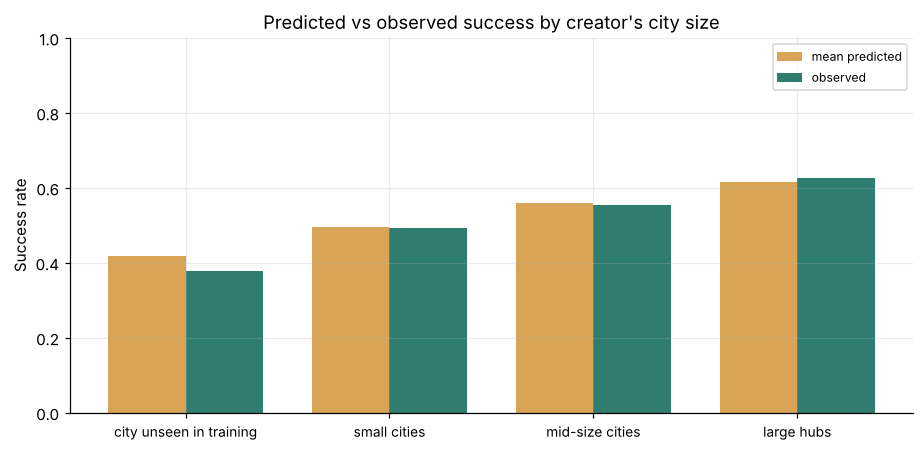

In [57]:
big = fair[fair["campaigns"] >= 100]
worst = big["gap (pts)"].abs().max()
check("Calibrated within 5 points in every city-size group", worst <= 5,
      f"largest group gap {worst:.1f} pts across {len(big)} groups of 100+ campaigns")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(fair)); w = 0.38
ax.bar(x - w / 2, fair["mean predicted"], w, color=SAND, label="mean predicted")
ax.bar(x + w / 2, fair["observed success"], w, color=TEAL, label="observed")
ax.set_xticks(x); ax.set_xticklabels(fair["city group"], fontsize=9)
ax.set_ylabel("Success rate"); ax.set_ylim(0, 1)
ax.set_title("Predicted vs observed success by creator's city size")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m4_fairness_city.png", dpi=130, bbox_inches="tight")
plt.show()

#### What does the city feature buy?

The model is calibrated in every group, so it is not *wrong* for small-city
creators. But the High-risk label lands on them far more often. Refit the
same model without the city-density feature to see what the feature is worth
and what dropping it would change.

In [58]:
from sklearn.metrics import accuracy_score
from src.modeling import make_models

keep = [c for c in rec.X_train.columns if c != "log_city_project_count"]
m_nc = make_final_model()
m_nc.fit(rec.X_train[keep], train["success"])
p_nc = m_nc.predict_proba(X_te[keep])[:, 1]
y_all = test["success"].to_numpy()

def high_share(p, g):
    return float(np.mean(p[(tt["city_group"] == g).to_numpy()] < BANDS[0][0]))

cmp = pd.DataFrame([
    {"model": "with city density (final)",
     "accuracy": accuracy_score(y_all, rec.holdout_p >= 0.5),
     "ROC-AUC": roc_auc_score(y_all, rec.holdout_p),
     "High risk: small cities": high_share(rec.holdout_p, "small cities"),
     "High risk: large hubs": high_share(rec.holdout_p, "large hubs")},
    {"model": "without city density",
     "accuracy": accuracy_score(y_all, p_nc >= 0.5),
     "ROC-AUC": roc_auc_score(y_all, p_nc),
     "High risk: small cities": high_share(p_nc, "small cities"),
     "High risk: large hubs": high_share(p_nc, "large hubs")},
])
cmp.round(3)

,model,accuracy,ROC-AUC,High risk: small cities,High risk: large hubs
0,with city density (final),0.816,0.898,0.415,0.274
1,without city density,0.816,0.896,0.373,0.306


In [59]:
tt.groupby("city_group").agg(
    campaigns=("p", "size"), median_goal=("goal", "median"),
    median_tiers=("levels", "median"),
    share_4_or_fewer_tiers=("levels", lambda x: (x <= 4).mean()),
    share_over_45_days=("duration_days", lambda x: (x > 45).mean())).loc[
    [g for g in order if (tt["city_group"] == g).any()]].round(3)

,campaigns,median_goal,median_tiers,share_4_or_fewer_tiers,share_over_45_days
city_group,,,,,
city unseen in training,453,4000.0,7.0,0.227,0.265
small cities,2408,3000.0,7.0,0.163,0.266
mid-size cities,2407,3500.0,8.0,0.153,0.283
large hubs,2408,4500.0,8.0,0.144,0.299


**Reading the fairness results.**

- **Calibration holds in every group.** For cities seen in training the
  average prediction is within 1.1 points of what happened. Cities unseen in
  training (453 campaigns) are 4.0 points too optimistic: inside the 5-point
  limit, and the group to watch.
- **But the High-risk label does not land evenly.** 41.5% of small-city
  creators are scored High risk against 27.4% in large hubs, about 1.5 times
  as often, and 51.9% in cities unseen in training. That reflects a real gap
  in outcomes (49.3% against 62.6% succeeded), not a calibration error, and
  the success rate among High-risk campaigns is similar across the
  seen-city groups (12–16%).
- **Dropping the city feature narrows the gap without closing it.** Accuracy
  stays at 81.6% and ROC-AUC falls from 0.898 to 0.896, while the High-risk
  share moves from 41.5% to 37.3% for small cities and from 27.4% to 30.6% for
  large hubs. Small-city campaigns ask for *less* (median $3,000 against
  $4,500), so goal size does not explain it.
- **It is a judgement call, and it is the team's to make.** City size cannot
  be changed and is never advised. The feature costs almost nothing to drop,
  so dropping it is defensible. The prototype keeps it; this is documented as
  a limitation and an open option.

### 15.5 Does every lever move the prediction the right way?

**Pass condition:** each candidate change raises the predicted chance for at
least 99% of the held-out campaigns it applies to. (Effects are estimated the
way the prototype estimates them: the advisor's change in points added to the
Random Forest's score.)

In [60]:
raw_test = test[RAW_COLUMNS].copy()

def share_raised(lever, value, rows):
    before = rec.predict_proba(rows)
    after = rec.what_if_proba(rows, rec.apply_lever(rows, lever, value), base=before)
    return float(np.mean(after > before)), len(rows)

recs = []
for f in GOAL_FACTORS:
    s, n = share_raised("goal", f, raw_test)
    recs.append({"lever": "goal", "change": f"x {f}", "campaigns": n, "share raised": s})
dur = raw_test["duration"]
for t_ in sorted(DURATION_TARGETS, reverse=True):
    rows = raw_test[(dur > DEFAULT_DURATION[1]) & (dur <= 60) & (dur > t_ + 0.5)]
    s, n = share_raised("duration", t_, rows)
    recs.append({"lever": "duration", "change": f"to {t_} days", "campaigns": n, "share raised": s})
for t_ in TIER_TARGETS:
    rows = raw_test[raw_test["levels"] <= t_ - MIN_TIER_ADDITION]
    rows = rows.sample(min(2000, len(rows)), random_state=0)
    s, n = share_raised("reward tiers", t_, rows)
    recs.append({"lever": "reward tiers", "change": f"to {t_} tiers", "campaigns": n, "share raised": s})
direction = pd.DataFrame(recs)
direction.round(4)

,lever,change,campaigns,share raised
0,goal,x 0.9,7676,0.9988
1,goal,x 0.75,7676,0.9988
2,goal,x 0.6,7676,0.9988
3,goal,x 0.5,7676,0.9990
4,duration,to 45 days,1247,1.0000
5,duration,to 35 days,2505,1.0000
6,duration,to 28 days,3287,1.0000
7,reward tiers,to 6 tiers,1211,1.0000
8,reward tiers,to 8 tiers,2000,1.0000
9,reward tiers,to 10 tiers,2000,1.0000


In [61]:
worst_share = direction["share raised"].min()
check("Every lever raises the prediction for 99%+ of eligible campaigns", worst_share >= 0.99,
      f"lowest share raised across {len(direction)} candidate changes: {worst_share:.1%}")

PASS  Every lever raises the prediction for 99%+ of eligible campaigns
      lowest share raised across 10 candidate changes: 99.9%


### 15.6 Is the evidence behind the levers stable over time?

The levers rest on patterns in the data. If a pattern held only in the early
years, advice built on it would be fitted to history. Split by **time** —
earlier campaigns against later ones — and re-check each pattern within goal
quartiles, using the earlier period's quartile cut-points for both.

**Pass condition:** in both periods and every goal quartile, (a) success
rises with the tier band, (b) exactly-30-day campaigns do worse than both
shorter and slightly longer ones, and (c) campaigns over 45 days are the
worst duration group.

In [62]:
cuts = train_c["goal"].quantile([0.25, 0.5, 0.75]).to_numpy()
def prep(df):
    d = df.copy()
    d["gq"] = pd.cut(d["goal"], [-np.inf, *cuts, np.inf], labels=["Q1", "Q2", "Q3", "Q4"])
    d["tier_b"] = pd.cut(d["levels"], [0, 4, 7, 10, 100], labels=["<=4", "5-7", "8-10", "11+"])
    d["dur_b"] = pd.cut(d["duration_days"], [0, 29.5, 30.5, 45, 100],
                        labels=["<=29", "30", "31-45", ">45"])
    return d

periods = {"earlier": prep(train_c), "later": prep(test_c)}
stab_rows, tables = [], {}
for name, d in periods.items():
    tier = d.pivot_table(index="gq", columns="tier_b", values="success", aggfunc="mean", observed=False)
    durp = d.pivot_table(index="gq", columns="dur_b", values="success", aggfunc="mean", observed=False)
    tables[name] = (tier, durp)
    stab_rows.append({
        "period": name,
        "campaigns": len(d),
        "(a) tiers rise in every quartile": bool(tier.apply(lambda r: r.dropna().is_monotonic_increasing, axis=1).all()),
        "(b) 30-day is a dip in every quartile": bool(((durp["30"] < durp["<=29"]) & (durp["30"] < durp["31-45"])).all()),
        "(c) >45 days worst in every quartile": bool((durp[">45"] == durp.min(axis=1)).all()),
    })
stability = pd.DataFrame(stab_rows)
stability

,period,campaigns,(a) tiers rise in every quartile,(b) 30-day is a dip in every quartile,(c) >45 days worst in every quartile
0,earlier,30702,True,True,True
1,later,7676,True,True,True


In [63]:
for name, (tier, durp) in tables.items():
    print(f"=== {name.upper()}: success by tier band, within goal quartile ===")
    print(tier.round(3).to_string())
    print(f"\n=== {name.upper()}: success by duration, within goal quartile ===")
    print(durp.round(3).to_string()); print()

=== EARLIER: success by tier band, within goal quartile ===
tier_b    <=4    5-7   8-10    11+
gq                                
Q1      0.615  0.691  0.726  0.782
Q2      0.413  0.617  0.680  0.776
Q3      0.205  0.454  0.588  0.694
Q4      0.091  0.243  0.372  0.524

=== EARLIER: success by duration, within goal quartile ===
dur_b   <=29     30  31-45    >45
gq                               
Q1     0.746  0.657  0.726  0.607
Q2     0.723  0.603  0.674  0.562
Q3     0.636  0.497  0.602  0.460
Q4     0.445  0.354  0.412  0.314

=== LATER: success by tier band, within goal quartile ===
tier_b    <=4    5-7   8-10    11+
gq                                
Q1      0.604  0.694  0.767  0.813
Q2      0.339  0.599  0.730  0.818
Q3      0.160  0.453  0.575  0.702
Q4      0.020  0.192  0.357  0.501

=== LATER: success by duration, within goal quartile ===
dur_b   <=29     30  31-45    >45
gq                               
Q1     0.762  0.641  0.698  0.633
Q2     0.733  0.609  0.664  0.469
Q3 

In [64]:
for col in ["(a) tiers rise in every quartile", "(b) 30-day is a dip in every quartile",
            "(c) >45 days worst in every quartile"]:
    check(f"Pattern stable across periods: {col[4:]}", bool(stability[col].all()),
          "earlier: " + str(bool(stability.loc[0, col])) + ", later: " + str(bool(stability.loc[1, col])))

PASS  Pattern stable across periods: tiers rise in every quartile
      earlier: True, later: True
PASS  Pattern stable across periods: 30-day is a dip in every quartile
      earlier: True, later: True
PASS  Pattern stable across periods: >45 days worst in every quartile
      earlier: True, later: True


### 15.7 How do the recommendations behave on at-risk campaigns?

Replay the engine on a random sample of held-out campaigns it scored High or
Moderate risk. **Pass condition:** no plan lowers a campaign's predicted
chance. Everything else here is *reported*, not graded — including the
share of plans where the lower goal reduces the funding floor, because that
is a cost the creator should know about.

In [65]:
pool = test[(rec.holdout_p < BANDS[1][0]) & (test["duration_days"] <= 60)]
sample = pool.sample(250, random_state=11)
rows = []
for _, r in sample.iterrows():
    a = rec.assess(campaign_from_row(r))
    adv = tuple(a.options.loc[a.options["recommended"], "lever"]) if len(a.options) else ()
    plan_p = a.plan["probability"] if a.plan else a.probability
    cut = (1 - a.plan["goal"] / a.campaign["goal"]) if (a.plan and a.plan["goal"] < a.campaign["goal"]) else 0.0
    rows.append({"p": a.probability, "plan_p": plan_p, "gain": (plan_p - a.probability) * 100,
                 "levers": adv, "n_levers": len(adv), "goal_cut": cut,
                 "floor_before": a.base_floor,
                 "floor_after": a.plan["funding_floor"] if a.plan else a.base_floor,
                 "band_before": a.band, "band_after": rec.band_of(plan_p),
                 "rf_direct": rec.probability(a.plan["campaign"]) if a.plan else a.probability})
plans = pd.DataFrame(rows)

order_b = [n for _, n in BANDS]
moved = (plans["band_after"].map(order_b.index) > plans["band_before"].map(order_b.index))
cut = plans.loc[plans["goal_cut"] > 0, "goal_cut"]
summary = pd.Series({
    "campaigns replayed": len(plans),
    "received at least one recommendation": f"{(plans['n_levers'] > 0).mean():.0%}",
    "mean plan gain (pts)": round(plans["gain"].mean(), 1),
    "median plan gain (pts)": round(plans["gain"].median(), 1),
    "smallest plan gain (pts)": round(plans["gain"].min(), 1),
    "plans that reach a better risk band": f"{moved.mean():.0%}",
    "plans that reach 50% or more": f"{(plans['plan_p'] >= 0.5).mean():.0%}",
    "plans that cut the goal": f"{(plans['goal_cut'] > 0).mean():.0%}",
    "median goal cut among those": f"{cut.median():.0%}" if len(cut) else "n/a",
    "plans where goal x probability FALLS": f"{(plans['floor_after'] < plans['floor_before']).mean():.0%}",
    "RF re-scoring the plan directly: median gain (pts)": round(((plans['rf_direct'] - plans['p']) * 100).median(), 1),
    "RF re-scoring the plan directly: share that also rise": f"{(plans['rf_direct'] > plans['p']).mean():.0%}",
})
summary.to_frame("value")

,value
campaigns replayed,250
received at least one recommendation,97%
mean plan gain (pts),8.2
median plan gain (pts),7.3
smallest plan gain (pts),0.0
plans that reach a better risk band,26%
plans that reach 50% or more,18%
plans that cut the goal,86%
median goal cut among those,25%
plans where goal x probability FALLS,19%


Lever combinations recommended:
goal, reward tiers              76
goal                            66
goal, duration, reward tiers    49
goal, duration                  24
reward tiers                    20
none                             7
duration, reward tiers           7
duration                         1


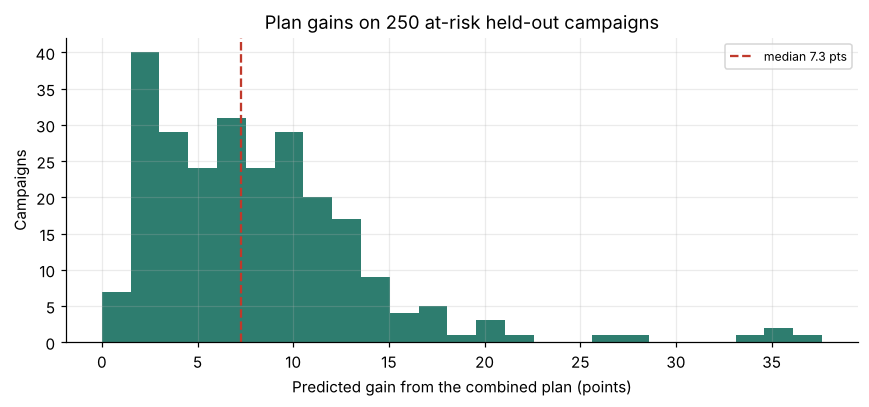

In [66]:
print("Lever combinations recommended:")
print(pd.Series([", ".join(l) if l else "none" for l in plans["levers"]]).value_counts().to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(plans["gain"], bins=25, color=TEAL)
ax.axvline(plans["gain"].median(), color=CORAL, ls="--", label=f"median {plans['gain'].median():.1f} pts")
ax.set_xlabel("Predicted gain from the combined plan (points)"); ax.set_ylabel("Campaigns")
ax.set_title("Plan gains on 250 at-risk held-out campaigns"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m4_plan_gains.png", dpi=130, bbox_inches="tight")
plt.show()

In [67]:
got_plan = plans[plans["n_levers"] > 0]
check("No plan lowers a campaign's predicted chance", bool((plans["gain"] >= 0).all()),
      f"smallest gain among the {len(got_plan)} campaigns that received a plan: "
      f"{got_plan['gain'].min():+.1f} pts ({len(plans) - len(got_plan)} got none)")

PASS  No plan lowers a campaign's predicted chance
      smallest gain among the 243 campaigns that received a plan: +2.0 pts (7 got none)


**What the replay shows.**

- **97% of at-risk campaigns get advice** (7 of 250 get none, because no
  single change cleared the 2-point bar).
- **The typical plan adds 7.3 points** (mean 8.2); 26% of plans reach a better
  risk band and 18% reach 50% or better. These are the engine's own
  estimates, not observed effects.
- **The two models mostly agree.** Re-scoring each planned campaign directly
  with the Random Forest also raises its chance in 90% of cases, by a median
  of 5.5 points against the engine's 7.3. The forest leans so heavily on
  `updates` that it responds less to the levers.
- **Most plans cut the goal** (86%), usually by 25%.
- **The cost the creator should know about:** in 19% of plans goal x
  probability **falls**, because the lower goal reduces what a successful
  campaign raises by more than the better odds make up for. The report states
  what a lower goal gives up.
- A minimum gain of zero appears only because 7 campaigns received no plan;
  no plan makes a campaign worse.

### 15.8 All checks

In [68]:
results = pd.DataFrame(checks)
results["result"] = np.where(results["passed"], "PASS", "FAIL")
print(f"{int(results['passed'].sum())} of {len(results)} checks passed\n")
results[["result", "check", "detail"]]

17 of 18 checks passed



,result,check,detail
0,PASS,No outcome column among the model's features,138 features inspected; offending: none
1,PASS,`updates` is the only campaign-time feature,campaign-time features in the model: ['updates']
2,PASS,No outcome field among the prototype's inputs,"inputs are ['goal', 'duration', 'levels', 'reward_levels', 'category', 'subcategory', ..."
3,PASS,Every outcome field is refused,"6 of 6 refused: ['backers', 'comments', 'funded_percentage', 'pledged', 'status', 'suc..."
4,PASS,"A missing updates plan is refused, not guessed",validate() without `updates` raises ValueError
5,PASS,"Timing features come from the launch date, not the end date",launch_date = end_date - duration holds exactly (max deviation 0 days 00:00:00)
6,PASS,What-if engine rebuilds the training matrix exactly,2000 rows re-featurised from raw inputs; max difference 0.0
7,PASS,Reproduces the Milestone 3 model (random split),"differences from Milestone 3: accuracy 0.0000, f1 0.0000, roc_auc 0.0000"
8,PASS,Holds up on later campaigns (chronological split),accuracy 0.816 random vs 0.805 chronological (gap 1.1 pts); chronological floor is 0.535
9,PASS,Calibrated within 5 points per decile (random split),largest gap 4.1 pts


In [69]:
(REPORTS / "m4_validation_summary.json").write_text(json.dumps(
    {"checks_passed": int(results["passed"].sum()), "checks_total": int(len(results)),
     "checks": checks}, indent=2))
fair.round(4).to_csv(REPORTS / "m4_fairness_by_city.csv", index=False)
stability.to_csv(REPORTS / "m4_lever_stability.csv", index=False)
direction.round(4).to_csv(REPORTS / "m4_lever_direction.csv", index=False)
summary.to_frame("value").to_csv(REPORTS / "m4_plan_behaviour.csv")
print("Wrote m4_validation_summary.json, m4_fairness_by_city, m4_lever_stability, "
      "m4_lever_direction, m4_plan_behaviour")

Wrote m4_validation_summary.json, m4_fairness_by_city, m4_lever_stability, m4_lever_direction, m4_plan_behaviour


### Task 15 — Summary

**17 of 18 checks pass.** The failure is reported, not hidden.

| Question | Answer |
|---|---|
| Only information a creator can supply? | **Yes** — no outcome column among the 138 features; `updates` is the only campaign-time feature and is required as a plan; all 6 outcome fields refused; a missing plan refused |
| Is the model the one from Milestone 3? | **Yes** — accuracy, F1 and ROC-AUC match the model card exactly |
| Does it hold on later campaigns? | **Yes on accuracy** (81.6% random, 80.5% chronological), **but** calibration misses by 5.6 points against a 5-point limit: **FAIL** |
| Are probabilities calibrated? | Yes on the random split (worst decile 4.1 points); pessimistic in the middle of the range on later data |
| Fair across city size? | Calibrated in every group (within 4.0 points), **but** small-city creators are flagged High risk about 1.5 times as often as large hubs — a documented judgement call |
| Do levers move predictions the right way? | Yes — 99.9% or more for every candidate change, once goal roundness is held fixed (Task 14, row 18) |
| Is the evidence stable over time? | **Yes** — the tier gradient, the 30-day dip and the long-campaign penalty hold in both periods and every goal quartile |
| Do plans behave sensibly? | No plan lowers a chance, and the Random Forest confirms 90% of plans when re-scoring them directly; **but 19% lower goal x probability** |

#### What this validation cannot show

- **That a creator will post the updates they plan.** The model's accuracy is
  measured with actual final update counts.
- **That following the advice works.** None of these checks can show that a
  creator who adds reward tiers or trims a goal would actually do better: the
  data contains no campaign that changed one thing and was observed again.
- **That the tier effect is causal.** It is the strongest and most stable
  lever pattern, and also the one most plausibly driven by creators who plan
  carefully.
- **That it works today.** Everything is 2009–2012.
- **That it is useful to creators.** Nobody outside the team has used it.

#### Handoff to the December wrap-up

`04_final_charts.ipynb` turns the strongest results into presentation-ready
figures, and the README summarises them.